**24ADI204- Data Science and Visualization**

**DATA VIZ HACK A BIT (2026-2027)**

Problem Statement:
**Air Quality Analysis and Pollution Prediction**

Domain: **Environment, Climate and Public Health**

**Team Members:**


**Ajayselvakumar K**  25BAD004      
**Ashwinkumar N**  25BAD015   
**Harish K**  25BAD033                  
**Logapradeep N D**  25BAD050

**SDG Aligned:**

SDG 3 – Good Health and Well-being


SDG 11 – Sustainable Cities and Communities


SDG 13 – Climate Action

Dataset Source: https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india

###Week 2-Know Your Data

Import Libraries

In [561]:
import pandas as pd
import numpy as np

Loading the Dataset:

In [562]:
df = pd.read_csv("/content/city_day.csv")

print("Dataset loaded successfully!")
print("Rows and Columns:", df.shape)

Dataset loaded successfully!
Rows and Columns: (29531, 16)


**Observations:**   The air-quality dataset is loaded from the city_day.csv file into a Pandas DataFrame named df. The output confirms that the dataset has been loaded successfully, with 29,531 rows and 16 columns. This original dataset serves as the starting point for the exploration and preprocessing stages.

Initial Records:

In [563]:
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


**Observations:** The first five records are displayed to get an initial view of the dataset and the information stored in each column. The records contain city names, dates, pollutant measurements and AQI details. Missing entries can already be noticed in columns such as PM2.5, PM10, NH3, AQI and AQI_Bucket, indicating that data completeness needs to be examined further.

Ending Records:

In [564]:
df.tail()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
29526,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,0.73,41.0,Good
29527,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,0.38,70.0,Satisfactory
29528,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,0.00,68.0,Satisfactory
29529,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,0.00,54.0,Satisfactory
29530,Visakhapatnam,2020-07-01,15.00,66.00,0.40,26.85,14.05,5.20,0.59,2.10,17.05,NaN,NaN,NaN,50.0,Good


**Observations:** The last five records are displayed to examine the entries at the end of the dataset. These records belong to Visakhapatnam and cover dates from 27 June 2020 to 1 July 2020. Along with the initial records, this provides a quick view of the dataset's date range and confirms that observations from different cities are included.

Inspecting Dataset Structure:

In [565]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB


**Observations:** The info() function provides details about the dataset, including the number of records, column names, data types and non-null values in each column. The dataset contains 29,531 entries across 16 columns, with numerical measurements as well as object-type information such as City, Date and AQI_Bucket. The varying non-null counts indicate that missing values are present in several columns. This structural overview helps identify the data types and completeness of the features before further processing.

Feature Types:

In [566]:
print("Feature Types")

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("\nNumerical Features:")
print(numerical_cols)

print("\nCategorical Features:")
print(categorical_cols)

Feature Types

Numerical Features:
['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI']

Categorical Features:
['City', 'Date', 'AQI_Bucket']


**Observations:** The dataset columns are examined based on their data types to distinguish numerical features from categorical or descriptive features. Pollutant measurements and AQI are numerical features that support statistical calculations and quantitative analysis. City, Date and AQI_Bucket provide location, time and air-quality category information. This classification is useful because different types of features require different approaches during analysis, visualization and preprocessing.

Missing Value Observation:

In [567]:
df.isnull().sum()

,0
City,0
Date,0
PM2.5,4598
PM10,11140
NO,3582
NO2,3585
NOx,4185
NH3,10328
CO,2059
SO2,3854


**Observations:** The missing-value count is calculated for each column to identify gaps in the dataset. Xylene has the highest number of missing values (18,109), followed by PM10 (11,140) and NH3 (10,328). This highlights the need for suitable missing-value treatment during data cleaning.

Duplicate Records Observation:

In [568]:
df.duplicated().sum()

np.int64(0)

**Observations:** The dataset is checked for exact duplicate rows using duplicated().sum(). The result is 0, confirming that no duplicate records are present. Therefore, duplicate removal is not required.

Time Period of Dataset Recorded:

In [569]:
print("Earliest Date:", df["Date"].min())
print("Latest Date:", df["Date"].max())

Earliest Date: 2015-01-01
Latest Date: 2020-07-01


**Observations:** The earliest and latest dates are identified to determine the dataset's time range. The records cover 1 January 2015 to 1 July 2020, providing approximately five and a half years of air-quality observations.

Cities Covered in the Dataset:

In [570]:
print("Cities Covered in the Dataset:")
cities = sorted(df["City"].dropna().unique())
for city in cities:
    print(city)
print("\nTotal Number of Cities:", len(cities))

Cities Covered in the Dataset:
Ahmedabad
Aizawl
Amaravati
Amritsar
Bengaluru
Bhopal
Brajrajnagar
Chandigarh
Chennai
Coimbatore
Delhi
Ernakulam
Gurugram
Guwahati
Hyderabad
Jaipur
Jorapokhar
Kochi
Kolkata
Lucknow
Mumbai
Patna
Shillong
Talcher
Thiruvananthapuram
Visakhapatnam

Total Number of Cities: 26


**Observations:** The unique city names are extracted and sorted alphabetically. The dataset includes air-quality observations from 26 Indian cities, providing geographical coverage for city-wise comparisons.

AQI Category Count:

In [571]:
print("AQI Categories Present in the Dataset:")
print(df["AQI_Bucket"].value_counts(dropna=False))

AQI Categories Present in the Dataset:
AQI_Bucket
Moderate        8829
Satisfactory    8224
NaN             4681
Poor            2781
Very Poor       2337
Good            1341
Severe          1338
Name: count, dtype: int64


**Observations:** The frequency of each AQI category is calculated, including missing entries. Moderate (8,829) and Satisfactory (8,224) are the most common categories, while 4,681 records have no assigned AQI category.

Data Quality Summary:

In [572]:
print("Data Quality Summary")
print("-" * 30)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Total Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Data Quality Summary
------------------------------
Total Rows: 29531
Total Columns: 16
Total Missing Values: 88488
Duplicate Rows: 0


**Observations:** A summary of the dataset reports 29,531 rows, 16 columns, 88,488 missing values and zero duplicate records. The high number of missing entries indicates that data cleaning is necessary before further analysis.

First Impression Report:

In [573]:
print("First Impression Report")
print("-" * 40)

print("1. The dataset contains", df.shape[0], "records and", df.shape[1], "features.")
print("2. The dataset contains air quality measurements from", df["City"].nunique(), "cities.")
print("3. Missing values are present in several pollutant and AQI-related columns.")
print("4. No duplicate records were identified.")
print("5. The dataset contains numerical pollutant measurements along with City, Date and AQI category information.")
print("6. Further cleaning is required before performing detailed analysis.")

First Impression Report
----------------------------------------
1. The dataset contains 29531 records and 16 features.
2. The dataset contains air quality measurements from 26 cities.
3. Missing values are present in several pollutant and AQI-related columns.
4. No duplicate records were identified.
5. The dataset contains numerical pollutant measurements along with City, Date and AQI category information.
6. Further cleaning is required before performing detailed analysis.


**Observations:** The initial exploration confirms that the dataset covers 26 cities and contains numerical pollutant measurements along with date and AQI information. Missing values are the main data-quality concern, making preprocessing necessary before detailed analysis.

**Week-3 The Cleaning Sprint**

1. Create a copy of Raw Dataset

In [574]:
df_clean = df.copy()

print("Working copy created successfully!")
print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)

Working copy created successfully!
Original Dataset Shape: (29531, 16)
Working Dataset Shape: (29531, 16)


Explanation: A separate working copy of the raw dataset is created to preserve the original data. Both datasets contain 29,531 rows and 16 columns, allowing cleaning operations to be performed without changing the source dataset.

2. Initial Data Quality Report:

In [575]:
print("Initial Data Quality Report")
print("-" * 40)

print("Total Rows:", df_clean.shape[0])
print("Total Columns:", df_clean.shape[1])
print("Total Missing Values:", df_clean.isnull().sum().sum())
print("Total Duplicate Rows:", df_clean.duplicated().sum())

Initial Data Quality Report
----------------------------------------
Total Rows: 29531
Total Columns: 16
Total Missing Values: 88488
Total Duplicate Rows: 0


Observations: The initial report shows 29,531 rows, 16 columns, 88,488 missing values and zero duplicate records. This indicates that missing data is the main issue that needs to be addressed during cleaning.

3. Missing Value Analysis:

In [576]:
import pandas as pd
import numpy as np


print("1. OVERALL MISSING VALUE ANALYSIS")
print("=" * 60)

total_records = len(df)
total_missing = df.isnull().sum().sum()
total_possible_values = df.shape[0] * df.shape[1]

print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Total Missing Values:", total_missing)

print(
    "Overall Missing Percentage:",
    round((total_missing / total_possible_values) * 100, 2), "%"
)



print("\n2. POLLUTANT-WISE MISSING VALUE ANALYSIS")
print("=" * 60)

pollutant_columns = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3",
    "Benzene", "Toluene", "Xylene"
]

pollutant_missing = pd.DataFrame({
    "Missing Count": df[pollutant_columns].isnull().sum(),
    "Missing Percentage": (
        df[pollutant_columns].isnull().mean() * 100
    ).round(2)
})

display(
    pollutant_missing.sort_values(
        "Missing Percentage",
        ascending=False
    )
)



print("\n3. CITY-WISE MISSING VALUE ANALYSIS")
print("=" * 60)

city_missing_count = df.groupby("City")[pollutant_columns].apply(
    lambda group: group.isnull().sum()
)

city_missing_percentage = df.groupby("City")[pollutant_columns].apply(
    lambda group: (group.isnull().mean() * 100).round(2)
)

city_missing_summary = pd.DataFrame({
    "Total Records": df.groupby("City").size()
})

for column in pollutant_columns:
    city_missing_summary[f"{column} Missing Count"] = (
        city_missing_count[column]
    )

    city_missing_summary[f"{column} Missing %"] = (
        city_missing_percentage[column]
    )

display(city_missing_summary)

1. OVERALL MISSING VALUE ANALYSIS
Total Records: 29531
Total Columns: 16
Total Missing Values: 88488
Overall Missing Percentage: 18.73 %

2. POLLUTANT-WISE MISSING VALUE ANALYSIS


,Missing Count,Missing Percentage
Xylene,18109,61.32
PM10,11140,37.72
NH3,10328,34.97
Toluene,8041,27.23
Benzene,5623,19.04
PM2.5,4598,15.57
NOx,4185,14.17
O3,4022,13.62
SO2,3854,13.05
NO2,3585,12.14



3. CITY-WISE MISSING VALUE ANALYSIS


,Total Records,PM2.5 Missing Count,PM2.5 Missing %,PM10 Missing Count,PM10 Missing %,NO Missing Count,NO Missing %,NO2 Missing Count,NO2 Missing %,NOx Missing Count,...,SO2 Missing Count,SO2 Missing %,O3 Missing Count,O3 Missing %,Benzene Missing Count,Benzene Missing %,Toluene Missing Count,Toluene Missing %,Xylene Missing Count,Xylene Missing %
City,,,,,,,,,,,,,,,,,,,,,
Ahmedabad,2009,628,31.26,1602,79.74,609,30.31,608,30.26,594,...,640,31.86,685,34.10,483,24.04,483,24.04,484,24.09
Aizawl,113,2,1.77,1,0.88,0,0.00,0,0.00,0,...,0,0.00,9,7.96,15,13.27,15,13.27,113,100.00
Amaravati,951,59,6.20,55,5.78,55,5.78,55,5.78,55,...,65,6.83,55,5.78,75,7.89,75,7.89,269,28.29
Amritsar,1221,128,10.48,63,5.16,93,7.62,44,3.60,289,...,168,13.76,115,9.42,195,15.97,212,17.36,213,17.44
Bengaluru,2009,146,7.27,360,17.92,6,0.30,6,0.30,4,...,6,0.30,144,7.17,266,13.24,93,4.63,2009,100.00
Bhopal,289,9,3.11,9,3.11,9,3.11,9,3.11,9,...,9,3.11,9,3.11,289,100.00,289,100.00,289,100.00
Brajrajnagar,938,185,19.72,173,18.44,243,25.91,234,24.95,175,...,193,20.58,203,21.64,173,18.44,938,100.00,938,100.00
Chandigarh,304,15,4.93,0,0.00,4,1.32,4,1.32,4,...,0,0.00,0,0.00,0,0.00,0,0.00,0,0.00
Chennai,2009,117,5.82,1707,84.97,36,1.79,36,1.79,36,...,36,1.79,49,2.44,285,14.19,253,12.59,2009,100.00


Findings: The dataset contains 88,488 missing values, representing 18.73% of all possible entries. Xylene has the highest missing percentage (61.32%), followed by PM10 (37.72%) and NH3 (34.97%).

4. Missing Value Treatment Decision:

In [577]:
missing_percentage = (df.isnull().mean() * 100).round(2)

print("MISSING VALUE TREATMENT DECISION")
print("-" * 60)

for column in missing_percentage[missing_percentage > 0].index:

    percentage = missing_percentage[column]

    if column == "Xylene":
        decision = "Drop due to very high missingness"

    elif column == "AQI":
        decision = "City-wise median imputation with overall median fallback"

    elif column == "AQI_Bucket":
        decision = "Derive missing category from treated AQI"

    elif column in ["PM10", "NH3"]:
        decision = "City-wise median imputation with overall median fallback"

    elif percentage < 5:
        decision = "Median imputation"

    elif percentage < 30:
        decision = "Evaluate and apply suitable imputation"

    else:
        decision = "Review and apply suitable treatment"

    print(f"{column}: {percentage:.2f}% - {decision}")

MISSING VALUE TREATMENT DECISION
------------------------------------------------------------
PM2.5: 15.57% - Evaluate and apply suitable imputation
PM10: 37.72% - City-wise median imputation with overall median fallback
NO: 12.13% - Evaluate and apply suitable imputation
NO2: 12.14% - Evaluate and apply suitable imputation
NOx: 14.17% - Evaluate and apply suitable imputation
NH3: 34.97% - City-wise median imputation with overall median fallback
CO: 6.97% - Evaluate and apply suitable imputation
SO2: 13.05% - Evaluate and apply suitable imputation
O3: 13.62% - Evaluate and apply suitable imputation
Benzene: 19.04% - Evaluate and apply suitable imputation
Toluene: 27.23% - Evaluate and apply suitable imputation
Xylene: 61.32% - Drop due to very high missingness
AQI: 15.85% - City-wise median imputation with overall median fallback
AQI_Bucket: 15.85% - Derive missing category from treated AQI


Analysis: Suitable treatment methods are selected based on the percentage and distribution of missing values in each column. Xylene is selected for removal due to its high missingness, while other pollutant values are handled using suitable imputation methods.

5. High-Missingness Pollutant Analysis Against AQI:

In [578]:
columns_to_check = ["Xylene", "PM10", "NH3"]

print("HIGH-MISSINGNESS POLLUTANT ANALYSIS AGAINST AQI")
print("-" * 60)

for column in columns_to_check:

    valid_data = df[["AQI", column]].dropna()

    missing_count = df[column].isnull().sum()
    missing_percentage = df[column].isnull().mean() * 100

    print(f"\nPollutant: {column}")
    print(f"Missing Values: {missing_count}")
    print(f"Missing Percentage: {missing_percentage:.2f}%")
    print(f"Available AQI-Pollutant Pairs: {len(valid_data)}")

    if len(valid_data) > 1:
        correlation = valid_data["AQI"].corr(valid_data[column])
        print(f"Correlation with AQI: {correlation:.3f}")
    else:
        print("Insufficient data for correlation.")

HIGH-MISSINGNESS POLLUTANT ANALYSIS AGAINST AQI
------------------------------------------------------------

Pollutant: Xylene
Missing Values: 18109
Missing Percentage: 61.32%
Available AQI-Pollutant Pairs: 9478
Correlation with AQI: 0.166

Pollutant: PM10
Missing Values: 11140
Missing Percentage: 37.72%
Available AQI-Pollutant Pairs: 17764
Correlation with AQI: 0.803

Pollutant: NH3
Missing Values: 10328
Missing Percentage: 34.97%
Available AQI-Pollutant Pairs: 18314
Correlation with AQI: 0.252


Insights: PM10 shows a strong correlation with AQI (0.803), while NH3 (0.252) and Xylene (0.166) show weaker relationships. This comparison helps assess the relevance of pollutants with high missing-value percentages.

6. Pollutant Missing Value Treatment:



In [579]:
import numpy as np
import pandas as pd

print("Applying Missing Value Treatment")
print("-" * 50)

# Keep the original raw dataset unchanged.
# Work on the cleaned copy.
df_clean = df_clean.copy()

# 1. Remove Xylene because of its very high missingness
df_clean = df_clean.drop(columns=["Xylene"], errors="ignore")

# 2. Impute PM10 and NH3 using city-wise medians
for column in ["PM10", "NH3"]:
    city_medians = df_clean.groupby("City")[column].transform("median")
    df_clean[column] = df_clean[column].fillna(city_medians)

    # Fallback: overall median
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

# 3. Impute other numerical pollutant columns
numerical_columns = [
    "PM2.5", "NO", "NO2", "NOx", "CO",
    "SO2", "O3", "Benzene", "Toluene", "NH3", "PM10"
]

for column in numerical_columns:
    if column in df_clean.columns:
        city_medians = df_clean.groupby("City")[column].transform("median")
        df_clean[column] = df_clean[column].fillna(city_medians)
        df_clean[column] = df_clean[column].fillna(df_clean[column].median())

# 4. Impute missing AQI using city-wise medians
aqi_city_medians = df_clean.groupby("City")["AQI"].transform("median")
df_clean["AQI"] = df_clean["AQI"].fillna(aqi_city_medians)

# Fallback for any city with no observed AQI median
df_clean["AQI"] = df_clean["AQI"].fillna(df_clean["AQI"].median())

# 5. Derive AQI_Bucket from AQI
# These thresholds match the classification already used in your notebook.
def classify_aqi(aqi):
    if pd.isna(aqi):
        return np.nan
    elif aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Satisfactory"
    elif aqi <= 200:
        return "Moderate"
    elif aqi <= 300:
        return "Poor"
    elif aqi <= 400:
        return "Very Poor"
    else:
        return "Severe"

# Fill missing categories based on AQI
missing_bucket = df_clean["AQI_Bucket"].isna()

df_clean.loc[missing_bucket, "AQI_Bucket"] = (
    df_clean.loc[missing_bucket, "AQI"].apply(classify_aqi)
)

print("Missing-value treatment completed.")
print("Dataset shape:", df_clean.shape)
print("Total remaining missing values:", df_clean.isna().sum().sum())

print("\nMissing values by column:")
display(df_clean.isna().sum()[df_clean.isna().sum() > 0])

Applying Missing Value Treatment
--------------------------------------------------
Missing-value treatment completed.
Dataset shape: (29531, 15)
Total remaining missing values: 0

Missing values by column:


,0


Explanation: Xylene is removed because 61.32% of its values are missing, while missing pollutant values are filled using suitable median-based methods. The cleaned dataset contains 29,531 rows and 15 columns, with no remaining missing values.

6.1. Pollutant Missing Value Verification:

In [580]:
print("Missing Values After Treatment")
print("-" * 50)

remaining_missing = df_clean.isnull().sum()
remaining_missing = remaining_missing[remaining_missing > 0]

if remaining_missing.empty:
    print("No missing values remain in the dataset.")
else:
    print(remaining_missing.to_string())

Missing Values After Treatment
--------------------------------------------------
No missing values remain in the dataset.


Observations: The verification confirms that no missing values remain in the cleaned dataset after treatment. This indicates that the pollutant missing-value handling process was completed successfully.

6.2. City-Wise PM10 and NH3 Imputation Verification:




In [581]:
for column in ["PM10", "NH3"]:
    print(f"\n{column} missing values by city:")
    missing_by_city = df.groupby("City")[column].agg(
        total="size",
        missing="count"
    )
    missing_by_city["missing"] = (
        df.groupby("City")[column].apply(lambda x: x.isna().sum())
    )
    missing_by_city["missing_percent"] = (
        missing_by_city["missing"] / missing_by_city["total"] * 100
    )
    print(missing_by_city.sort_values("missing_percent", ascending=False).round(2))


PM10 missing values by city:
                    total  missing  missing_percent
City                                               
Lucknow              2009     2009           100.00
Patna                1858     1667            89.72
Chennai              2009     1707            84.97
Ahmedabad            2009     1602            79.74
Mumbai               2009     1246            62.02
Gurugram             1679      939            55.93
Jorapokhar           1169      275            23.52
Shillong              310       69            22.26
Talcher               925      179            19.35
Brajrajnagar          938      173            18.44
Bengaluru            2009      360            17.92
Hyderabad            2006      355            17.70
Visakhapatnam        1462      236            16.14
Kolkata               814       55             6.76
Amaravati             951       55             5.78
Amritsar             1221       63             5.16
Delhi                2009       77

Analysis: Missing values in PM10 and NH3 are examined separately for each city. The results show that missingness varies across cities, supporting the use of city-wise median imputation where sufficient values are available.

6.3. Compare Overall and City-Wise Medians

In [582]:
for column in ["PM10", "NH3"]:
    print(f"\n{column}")
    print("-" * 40)

    overall_median = df[column].median()
    city_medians = df.groupby("City")[column].median()

    print(f"Overall median: {overall_median:.2f}")
    print("Cities without observed values:",
          city_medians[city_medians.isna()].index.tolist())

    print("\nCity-wise medians:")
    print(city_medians.round(2).to_string())


PM10
----------------------------------------
Overall median: 95.68
Cities without observed values: ['Lucknow']

City-wise medians:
City
Ahmedabad             107.96
Aizawl                 18.96
Amaravati              64.90
Amritsar               98.09
Bengaluru              77.36
Bhopal                120.48
Brajrajnagar          119.41
Chandigarh             78.94
Chennai                50.24
Coimbatore             36.22
Delhi                 216.73
Ernakulam              44.64
Gurugram              176.09
Guwahati               87.98
Hyderabad              94.48
Jaipur                116.82
Jorapokhar            124.64
Kochi                  45.66
Kolkata                81.77
Lucknow                  NaN
Mumbai                 77.88
Patna                 118.02
Shillong               26.93
Talcher               129.07
Thiruvananthapuram     48.33
Visakhapatnam         100.68

NH3
----------------------------------------
Overall median: 15.85
Cities without observed values: ['Ahmeda

Findings: The city-wise medians differ from the overall median for PM10 and NH3, showing that pollutant levels vary between cities. City-wise median imputation can therefore preserve local differences better than using a single overall median.

7. AQI Missing Value Analysis:

In [583]:
print("AQI Missing Value Analysis")
print("-" * 40)
print("Total rows:", len(df))
print("Missing AQI values:", df["AQI"].isnull().sum())
print("Missing AQI percentage:", round(df["AQI"].isnull().mean() * 100, 2), "%")
print("Rows with available AQI:", df["AQI"].notnull().sum())

AQI Missing Value Analysis
----------------------------------------
Total rows: 29531
Missing AQI values: 4681
Missing AQI percentage: 15.85 %
Rows with available AQI: 24850


Observations: The original dataset contains 4,681 missing AQI values, representing 15.85% of the records. A total of 24,850 records have available AQI values, making AQI treatment an important part of data cleaning.

7.1. AQI and AQI_Bucket Consistency Check:

In [584]:
valid = df.dropna(subset=["AQI", "AQI_Bucket"])
print("Rows with both AQI and AQI_Bucket:", len(valid))
print("\nAQI Bucket counts:")
print(valid["AQI_Bucket"].value_counts())
print("\nAQI values by bucket:")
print(valid.groupby("AQI_Bucket")["AQI"].agg(["min", "max", "count"]))

Rows with both AQI and AQI_Bucket: 24850

AQI Bucket counts:
AQI_Bucket
Moderate        8829
Satisfactory    8224
Poor            2781
Very Poor       2337
Good            1341
Severe          1338
Name: count, dtype: int64

AQI values by bucket:
                min     max  count
AQI_Bucket                        
Good           13.0    50.0   1341
Moderate      101.0   200.0   8829
Poor          201.0   300.0   2781
Satisfactory   51.0   100.0   8224
Severe        401.0  2049.0   1338
Very Poor     301.0   400.0   2337


Analysis: The AQI values are compared with their corresponding categories to examine whether the category ranges are consistent. Moderate (8,829) and Satisfactory (8,224) are the most frequent categories among records with both values available.

8. Correlation Comparison Before and After Median Imputation

In [585]:
for column in ["PM10", "NH3"]:
    original_corr = df[["AQI", column]].dropna().corr().iloc[0, 1]
    imputed_data = df[["AQI", column]].copy()
    imputed_data[column] = imputed_data[column].fillna(df[column].median())
    imputed_corr = imputed_data.corr().iloc[0, 1]

    print(f"\n{column}")
    print(f"Correlation before imputation: {original_corr:.3f}")
    print(f"Correlation after imputation:  {imputed_corr:.3f}")


PM10
Correlation before imputation: 0.803
Correlation after imputation:  0.456

NH3
Correlation before imputation: 0.252
Correlation after imputation:  0.086


Insights: After median imputation, the PM10–AQI correlation decreases from 0.803 to 0.456, while the NH3–AQI correlation decreases from 0.252 to 0.086. This shows that median imputation can influence the observed relationships between variables.

9. Outlier Detection Using Boxplots:

Outlier Detection Using Boxplots


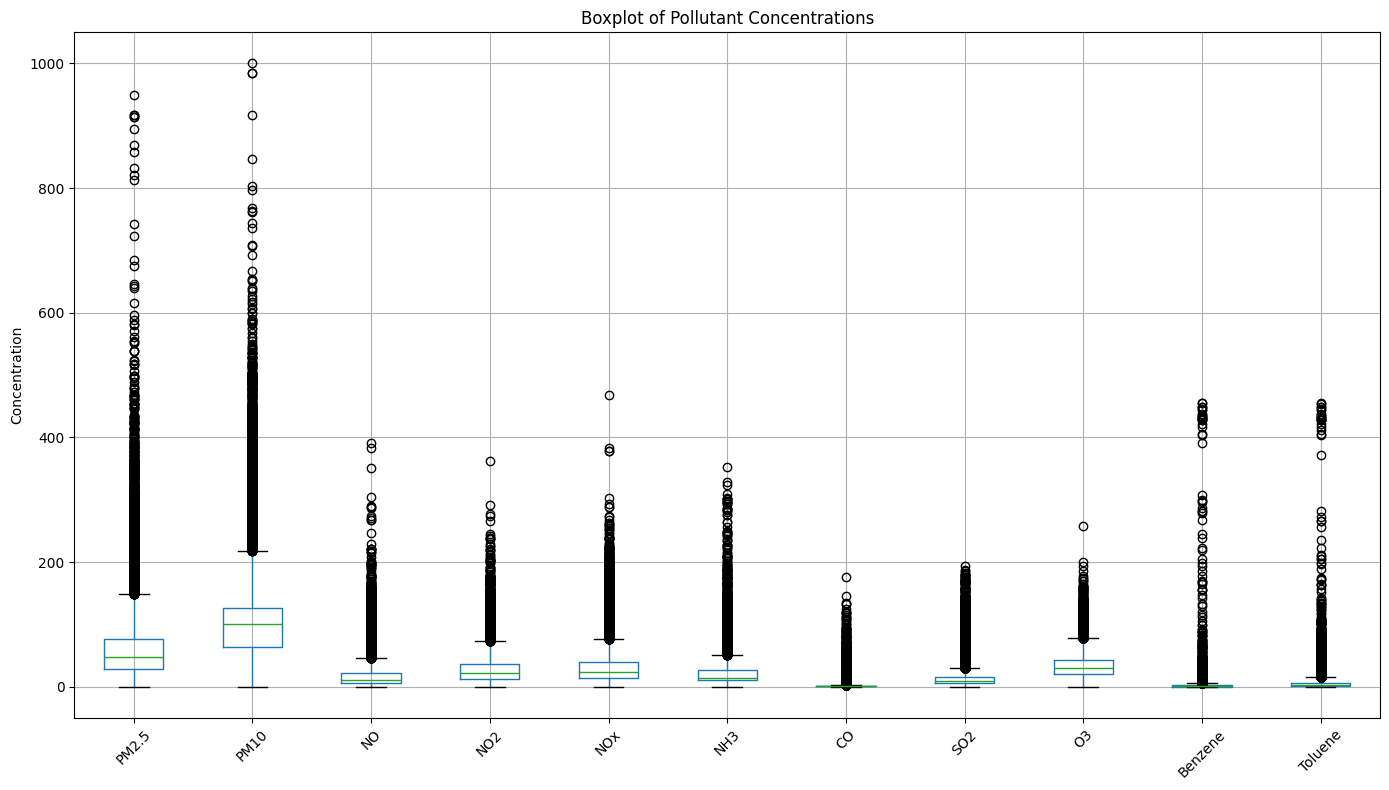

In [586]:
import matplotlib.pyplot as plt

print("Outlier Detection Using Boxplots")

numerical_pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3",
    "Benzene", "Toluene"
]

plt.figure(figsize=(14, 8))
df_clean[numerical_pollutants].boxplot()

plt.title("Boxplot of Pollutant Concentrations")
plt.ylabel("Concentration")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Observations: Boxplots are generated for the major pollutant columns to visually identify unusually high or low values. Several potential outliers can be observed, indicating differences in pollutant concentration levels.

10. Outlier Count Using the IQR Method:

In [587]:
print("Outlier Count by Pollutant")
print("-" * 40)

for column in numerical_pollutants:
    q1 = df_clean[column].quantile(0.25)
    q3 = df_clean[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df_clean[column] < lower) | (df_clean[column] > upper)).sum()
    percentage = count / df_clean[column].notna().sum() * 100

    print(f"{column}: {count} outliers ({percentage:.2f}%)")

Outlier Count by Pollutant
----------------------------------------
PM2.5: 2234 outliers (7.56%)
PM10: 2095 outliers (7.09%)
NO: 2084 outliers (7.06%)
NO2: 1327 outliers (4.49%)
NOx: 2061 outliers (6.98%)
NH3: 1631 outliers (5.52%)
CO: 2954 outliers (10.00%)
SO2: 3183 outliers (10.78%)
O3: 1059 outliers (3.59%)
Benzene: 2052 outliers (6.95%)
Toluene: 3831 outliers (12.97%)


Findings: The IQR method identifies potential outliers in all the selected pollutant columns. Toluene has the highest outlier percentage (12.97%), followed by SO2 (10.78%) and CO (10.00%).

11. Z-Score Outlier Detection:

In [588]:
from scipy.stats import zscore

print("Outlier Detection Using Z-Score")
print("-" * 50)

z_scores = df_clean[numerical_pollutants].apply(
    lambda column: zscore(column, nan_policy="omit")
)

outlier_counts = (abs(z_scores) > 3).sum()

print(outlier_counts[outlier_counts > 0].sort_values(ascending=False).to_string())


Outlier Detection Using Z-Score
--------------------------------------------------
NO         675
PM10       667
NOx        659
PM2.5      614
SO2        595
CO         537
NO2        515
NH3        482
O3         431
Toluene    322
Benzene    110


Findings: The Z-score method identifies values that are more than three standard deviations from the mean. NO has the highest number of detected outliers (675), followed by PM10 (667) and NOx (659).

12. Outlier Summary:

In [589]:
print("Outlier Detection Summary")
print("-" * 50)

print("1. Boxplot (IQR) Method: Identified potential outliers beyond the IQR limits.")
print("2. Z-Score Method: Identified potential outliers with absolute Z-scores greater than 3.")
print("3. Treatment Decision: Outliers were retained because extreme values may represent genuine pollution events.")
print("4. Limitation: Statistical methods alone cannot confirm whether an outlier is a data error.")
print("5. Future Action: Investigate suspicious values using data validation and environmental context.")


Outlier Detection Summary
--------------------------------------------------
1. Boxplot (IQR) Method: Identified potential outliers beyond the IQR limits.
2. Z-Score Method: Identified potential outliers with absolute Z-scores greater than 3.
3. Treatment Decision: Outliers were retained because extreme values may represent genuine pollution events.
4. Limitation: Statistical methods alone cannot confirm whether an outlier is a data error.
5. Future Action: Investigate suspicious values using data validation and environmental context.


Inference: Both IQR and Z-score methods identify potential outliers in the pollutant measurements. Since extreme values may represent genuine pollution events, statistical detection alone is not sufficient to classify them as errors.

13. IQR-Based Outlier Capping:

In [590]:
numerical_pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene"
]

for col in numerical_pollutants:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1
    lower = max(0, Q1 - 1.5 * IQR)
    upper = Q3 + 1.5 * IQR

    df_clean[col] = df_clean[col].clip(lower, upper)

print("IQR outlier capping completed!")
print("Dataset shape:", df_clean.shape)

IQR outlier capping completed!
Dataset shape: (29531, 15)


Explanation: The IQR method is used to cap extreme values in the selected pollutant columns within calculated lower and upper limits. This reduces the influence of extreme observations while retaining all 29,531 records.

13.1. Outlier Visualization After IQR Capping:

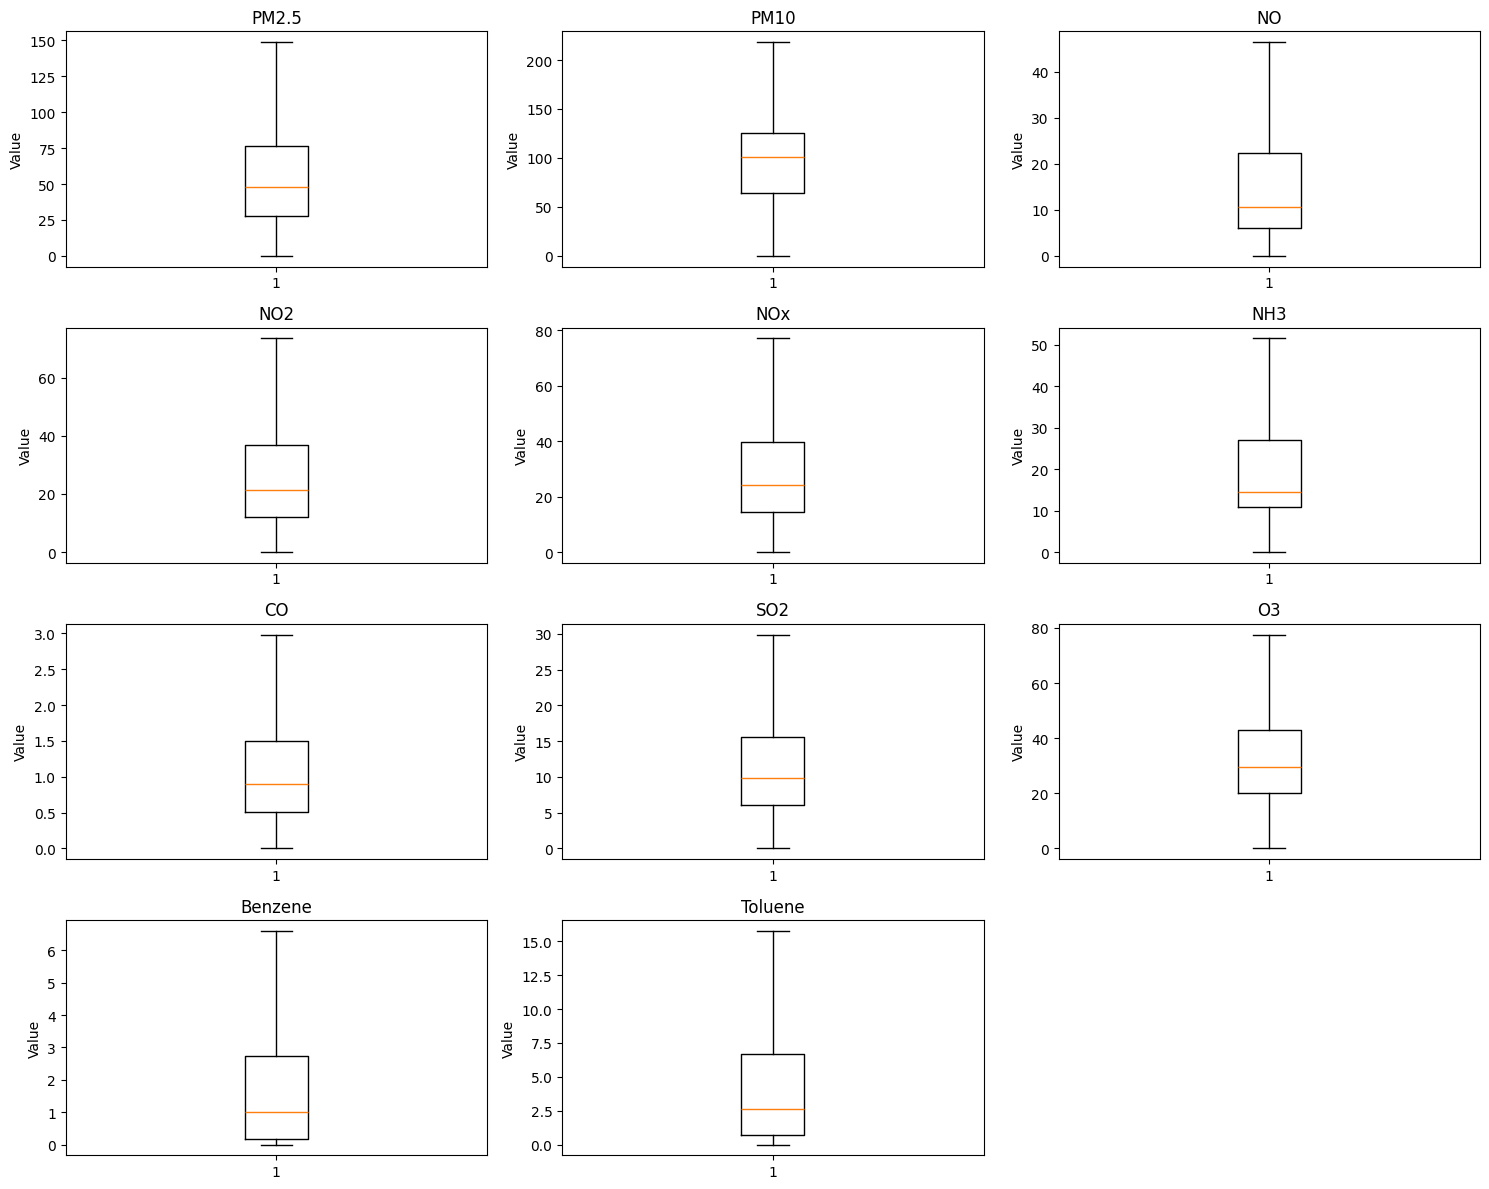

In [591]:
import matplotlib.pyplot as plt

numerical_pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene"
]

plt.figure(figsize=(15, 12))

for i, col in enumerate(numerical_pollutants, 1):
    plt.subplot(4, 3, i)
    plt.boxplot(df_clean[col].dropna())
    plt.title(col)
    plt.ylabel("Value")

plt.tight_layout()
plt.show()

Observations:Boxplots are generated again after IQR-based capping to examine the effect of the treatment. The visualizations help confirm that extreme pollutant values have been restricted to the calculated limits.

14. AQI Extreme Value Investigation:

In [592]:
high_aqi = df[df["AQI"] > 500]

print("AQI values above 500:", len(high_aqi))
print("\nHighest AQI values:")
print(high_aqi[["City", "Date", "AQI", "AQI_Bucket"]].sort_values("AQI", ascending=False).head(15))

AQI values above 500: 543

Highest AQI values:
           City        Date     AQI AQI_Bucket
1145  Ahmedabad  2018-02-19  2049.0     Severe
1136  Ahmedabad  2018-02-10  1917.0     Severe
560   Ahmedabad  2016-07-14  1842.0     Severe
1048  Ahmedabad  2017-11-14  1747.0     Severe
1463  Ahmedabad  2019-01-03  1719.0     Severe
1417  Ahmedabad  2018-11-18  1672.0     Severe
1420  Ahmedabad  2018-11-21  1646.0     Severe
1407  Ahmedabad  2018-11-08  1630.0     Severe
1127  Ahmedabad  2018-02-01  1613.0     Severe
1746  Ahmedabad  2019-10-13  1595.0     Severe
1047  Ahmedabad  2017-11-13  1577.0     Severe
1391  Ahmedabad  2018-10-23  1561.0     Severe
1451  Ahmedabad  2018-12-22  1558.0     Severe
1412  Ahmedabad  2018-11-13  1548.0     Severe
1481  Ahmedabad  2019-01-21  1537.0     Severe


Findings: A total of 543 records have AQI values above 500, with the highest recorded value reaching 2,049. These extreme observations are examined further to understand their city-wise distribution and possible significance.

14.1. City-Wise Analysis of AQI Values Above 500:

In [593]:
high_aqi = df[df["AQI"] > 500]

print("AQI values above 500 by city:")
print(high_aqi.groupby("City").size().sort_values(ascending=False))

print("\nPercentage of each city's records above 500:")
city_total = df.groupby("City").size()
city_extreme = high_aqi.groupby("City").size()

result = (city_extreme / city_total * 100).dropna().sort_values(ascending=False)
print(result.round(2))

AQI values above 500 by city:
City
Ahmedabad     412
Delhi          48
Patna          25
Gurugram       22
Lucknow        15
Jorapokhar      7
Amritsar        4
Hyderabad       4
Talcher         4
Guwahati        2
dtype: int64

Percentage of each city's records above 500:
City
Ahmedabad     20.51
Delhi          2.39
Patna          1.35
Gurugram       1.31
Lucknow        0.75
Jorapokhar     0.60
Talcher        0.43
Guwahati       0.40
Amritsar       0.33
Hyderabad      0.20
dtype: float64


Analysis: Ahmedabad accounts for 412 of the 543 records with AQI values above 500, making it the city with the highest number of extreme observations. Delhi follows with 48 records, showing that extreme AQI values are concentrated in certain cities.

14.2. Ahmedabad's AQI Values Above 500 Over Time:

In [594]:
ahmedabad_extreme = df[
    (df["City"] == "Ahmedabad") &
    (df["AQI"] > 500)
].sort_values("Date")

print("AHMEDABAD: AQI VALUES ABOVE 500")
print("-" * 50)

print("Total records:", len(ahmedabad_extreme))

if not ahmedabad_extreme.empty:

    print("\nAQI Summary:")
    print(ahmedabad_extreme["AQI"].describe().round(2))

    print("\nEarliest 5 Records:")
    display(
        ahmedabad_extreme[
            ["Date", "AQI", "AQI_Bucket"]
        ].head(5)
    )

    print("\nLatest 5 Records:")
    display(
        ahmedabad_extreme[
            ["Date", "AQI", "AQI_Bucket"]
        ].tail(5)
    )

else:
    print("No records found with AQI above 500.")

AHMEDABAD: AQI VALUES ABOVE 500
--------------------------------------------------
Total records: 412

AQI Summary:
count     412.00
mean      811.08
std       310.09
min       502.00
25%       565.00
50%       702.50
75%       958.25
max      2049.00
Name: AQI, dtype: float64

Earliest 5 Records:


,Date,AQI,AQI_Bucket
30,2015-01-31,514.0,Severe
31,2015-02-01,782.0,Severe
32,2015-02-02,914.0,Severe
33,2015-02-03,660.0,Severe
43,2015-02-13,510.0,Severe



Latest 5 Records:


,Date,AQI,AQI_Bucket
1882,2020-02-26,983.0,Severe
1883,2020-02-27,1262.0,Severe
1884,2020-02-28,962.0,Severe
1887,2020-03-02,508.0,Severe
1904,2020-03-19,988.0,Severe


Findings: Ahmedabad has 412 records with AQI values above 500, ranging from 502 to 2,049. The average AQI of these extreme records is 811.08, indicating several very high pollution observations across the study period.

14.3. AQI Category Analysis for Extreme Values:

In [595]:
print(df[df["AQI"] > 500]["AQI_Bucket"].value_counts(dropna=False))

print("\nAQI category and value summary:")
print(
    df[df["AQI"] > 500]
    .groupby("AQI_Bucket", dropna=False)["AQI"]
    .agg(["min", "max", "count"])
)

AQI_Bucket
Severe    543
Name: count, dtype: int64

AQI category and value summary:
              min     max  count
AQI_Bucket                      
Severe      501.0  2049.0    543


Observations: All 543 records with AQI values above 500 belong to the Severe category. Their AQI values range from 501 to 2,049, confirming that these observations fall within the most severe category in the dataset.

15. AQI Outlier Handling and AQI_Bucket Validation:

In [596]:
import numpy as np
import pandas as pd

print("AQI Outlier Handling and AQI_Bucket Validation")
print("-" * 55)

# 1. Check AQI before capping
Q1 = df_clean["AQI"].quantile(0.25)
Q3 = df_clean["AQI"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = max(0, Q1 - 1.5 * IQR)
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df_clean["AQI"] < lower_bound) |
    (df_clean["AQI"] > upper_bound)
)

print("Potential AQI outliers before capping:", outlier_mask.sum())
print("Lower capping bound:", round(lower_bound, 2))
print("Upper capping bound:", round(upper_bound, 2))

# 2. Apply IQR capping to AQI
df_clean["AQI"] = df_clean["AQI"].clip(
    lower=lower_bound,
    upper=upper_bound
)

print("\nAQI outlier capping completed.")
print("Minimum AQI after capping:", df_clean["AQI"].min())
print("Maximum AQI after capping:", df_clean["AQI"].max())

# 3. Recalculate AQI_Bucket from the capped AQI
def classify_aqi(aqi):
    if pd.isna(aqi):
        return np.nan
    elif aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Satisfactory"
    elif aqi <= 200:
        return "Moderate"
    elif aqi <= 300:
        return "Poor"
    elif aqi <= 400:
        return "Very Poor"
    else:
        return "Severe"

df_clean["AQI_Bucket"] = df_clean["AQI"].apply(classify_aqi)

# 4. Validate results
print("\nMissing AQI values:", df_clean["AQI"].isna().sum())
print("Missing AQI_Bucket values:", df_clean["AQI_Bucket"].isna().sum())

print("\nAQI_Bucket counts after treatment:")
display(df_clean["AQI_Bucket"].value_counts(dropna=False))

print("\nFinal AQI summary:")
display(df_clean["AQI"].describe())

AQI Outlier Handling and AQI_Bucket Validation
-------------------------------------------------------
Potential AQI outliers before capping: 1465
Lower capping bound: 0
Upper capping bound: 391.0

AQI outlier capping completed.
Minimum AQI after capping: 13.0
Maximum AQI after capping: 391.0

Missing AQI values: 0
Missing AQI_Bucket values: 0

AQI_Bucket counts after treatment:


,count
AQI_Bucket,
Moderate,10338
Satisfactory,9979
Very Poor,4350
Poor,3416
Good,1448



Final AQI summary:


,AQI
count,29531.000000
mean,157.334225
std,102.737099
min,13.000000
25%,86.000000
50%,117.000000
75%,208.000000
max,391.000000


Explanation: AQI values are capped using the IQR upper limit of 391, and the AQI categories are validated after treatment. The final AQI values range from 13 to 391, with no missing AQI or AQI_Bucket values remaining.

16. Final Data Quality Check:

In [597]:
print("Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:", df_clean.duplicated().sum())

print("\nFirst 5 Rows:")
display(df_clean.head())

Dataset Shape: (29531, 15)

Missing Values:
City          0
Date          0
PM2.5         0
PM10          0
NO            0
NO2           0
NOx           0
NH3           0
CO            0
SO2           0
O3            0
Benzene       0
Toluene       0
AQI           0
AQI_Bucket    0
dtype: int64

Duplicate Rows: 0

First 5 Rows:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,58.37,107.96,0.92,18.22,17.15,14.5,0.920,27.640,77.6225,0.000,0.02,384.5,Very Poor
1,Ahmedabad,2015-01-02,58.37,107.96,0.97,15.69,16.46,14.5,0.970,24.550,34.0600,3.680,5.50,384.5,Very Poor
2,Ahmedabad,2015-01-03,58.37,107.96,17.40,19.30,29.70,14.5,2.985,29.070,30.7000,6.605,15.78,384.5,Very Poor
3,Ahmedabad,2015-01-04,58.37,107.96,1.70,18.48,17.97,14.5,1.700,18.590,36.0800,4.430,10.14,384.5,Very Poor
4,Ahmedabad,2015-01-05,58.37,107.96,22.10,21.42,37.76,14.5,2.985,29.925,39.3100,6.605,15.78,384.5,Very Poor


Observations: The final cleaned dataset contains 29,531 rows and 15 columns, with zero missing values and zero duplicate records. This confirms that the missing-value treatment and outlier-handling steps have been completed.

17. Save the Final Cleaned Dataset:

In [598]:
output_file = "city_day_cleaned.csv"

df_clean.to_csv(output_file, index=False)

print("Final cleaned dataset saved successfully!")
print("File:", output_file)
print("Dataset shape:", df_clean.shape)
print("Total missing values:", df_clean.isna().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

Final cleaned dataset saved successfully!
File: city_day_cleaned.csv
Dataset shape: (29531, 15)
Total missing values: 0
Duplicate rows: 0


Findings: The cleaned dataset is saved as `city_day_cleaned.csv` for use in the next stages of analysis. The saved file contains 29,531 rows and 15 columns, with no missing values or duplicate records.

**Week-4 EDA Deep Dive**

Cleaned Dataset Shape:

In [599]:
print("Cleaned Dataset Shape:", df_clean.shape)

Cleaned Dataset Shape: (29531, 15)


Summary Statistics:

In [600]:
summary_stats = df_clean.describe().T

print(summary_stats.to_string())

           count        mean         std    min     25%      50%      75%       max
PM2.5    29531.0   58.498269   38.898551   0.04  28.080   48.170   76.345  148.7425
PM10     29531.0  104.587980   52.991602   0.01  63.775  100.685  125.615  218.3750
NO       29531.0   15.270978   12.698584   0.02   6.100   10.580   22.220   46.4000
NO2      29531.0   26.770733   18.686870   0.01  12.080   21.460   36.650   73.5050
NOx      29531.0   29.091632   20.674907   0.00  14.495   24.290   39.510   77.0325
NH3      29531.0   19.944800   13.365252   0.01  10.770   14.500   27.070   51.5200
CO       29531.0    1.118912    0.865943   0.00   0.510    0.900    1.500    2.9850
SO2      29531.0   12.363020    8.445002   0.01   6.050    9.900   15.600   29.9250
O3       29531.0   33.093970   18.142817   0.01  19.960   29.620   43.025   77.6225
Benzene  29531.0    1.774444    2.009448   0.00   0.180    1.020    2.750    6.6050
Toluene  29531.0    4.720366    5.317510   0.00   0.680    2.650    6.720   

**Observations:** Summary statistics are generated for the cleaned dataset to examine the count, mean, standard deviation, minimum, maximum and quartiles of each numerical feature. This provides an overview of pollutant concentrations and AQI values.

**Univariate Visualizations:**

1. AQI Distribution (Histogram):

U1. AQI Distribution


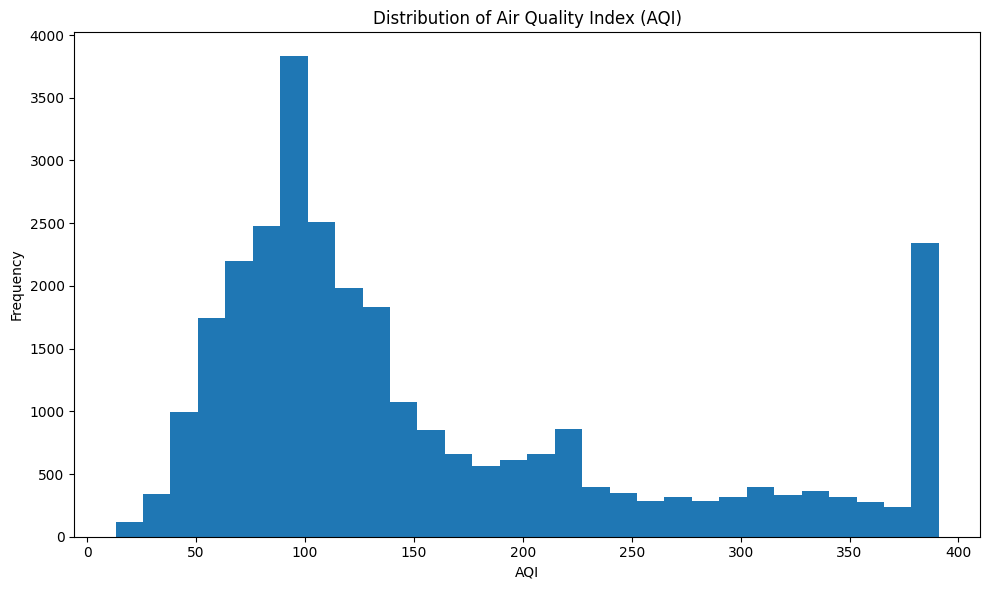

In [601]:
import matplotlib.pyplot as plt

print("U1. AQI Distribution")

plt.figure(figsize=(10, 6))

plt.hist(df_clean["AQI"], bins=30)

plt.xlabel("AQI")
plt.ylabel("Frequency")
plt.title("Distribution of Air Quality Index (AQI)")

plt.tight_layout()
plt.show()

**Findings:** The AQI histogram shows how frequently different AQI values occur in the dataset. It helps identify the overall distribution of air-quality levels and whether the values are concentrated in a particular range.

2. AQI Boxplot:

U2. AQI Boxplot


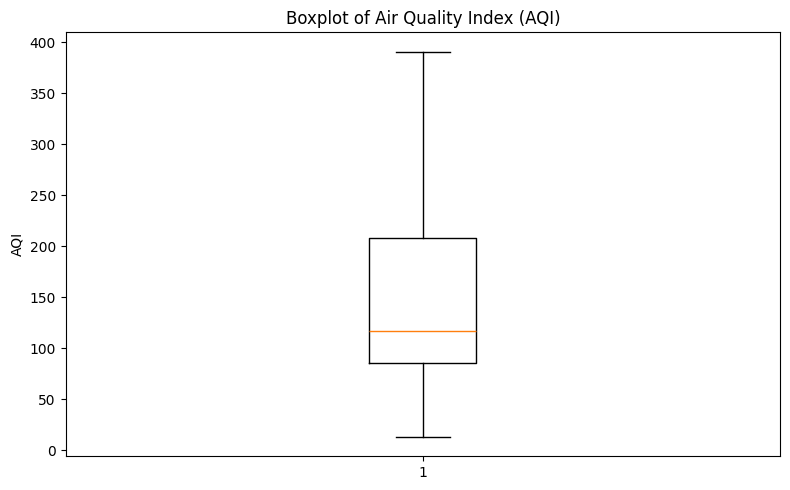

In [602]:
print("U2. AQI Boxplot")

plt.figure(figsize=(8, 5))

plt.boxplot(df_clean["AQI"])

plt.ylabel("AQI")
plt.title("Boxplot of Air Quality Index (AQI)")

plt.tight_layout()
plt.show()

**Findings:** The boxplot displays the median, spread and potential extreme values of AQI. It provides a quick view of the variation in air-quality levels and helps identify possible outliers.

3. AQI Category Distribution:

U3. AQI Category Distribution


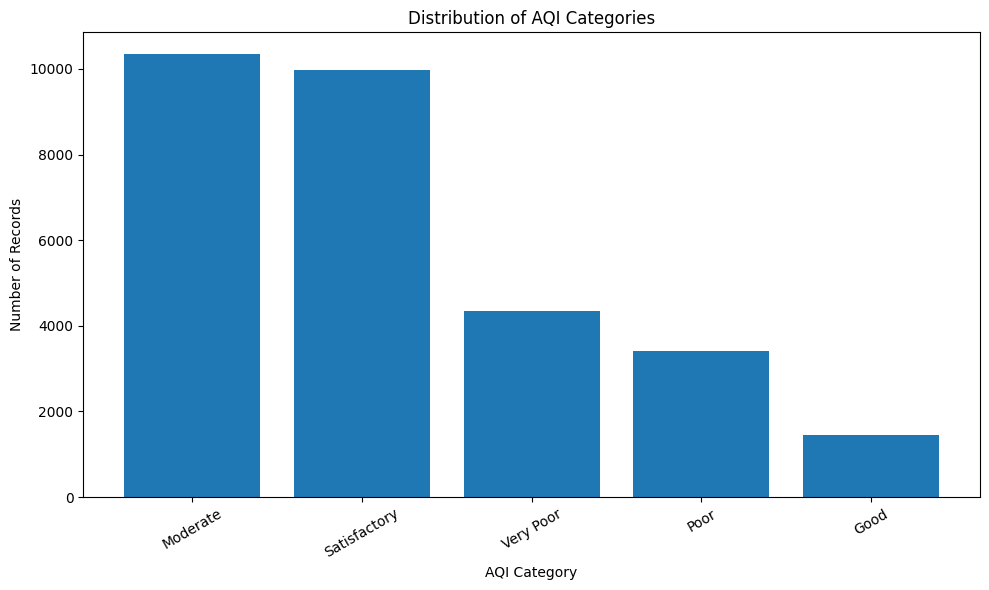

In [603]:
print("U3. AQI Category Distribution")

category_counts = df_clean["AQI_Bucket"].value_counts()

plt.figure(figsize=(10, 6))

plt.bar(category_counts.index, category_counts.values)

plt.xlabel("AQI Category")
plt.ylabel("Number of Records")
plt.title("Distribution of AQI Categories")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Observations:** The chart displays the number of records in each AQI category, such as Good, Satisfactory, Moderate, Poor, Very Poor and Severe. It helps compare the frequency of different air-quality classifications.

4. PM2.5 Distribution:

U4. PM2.5 Distribution


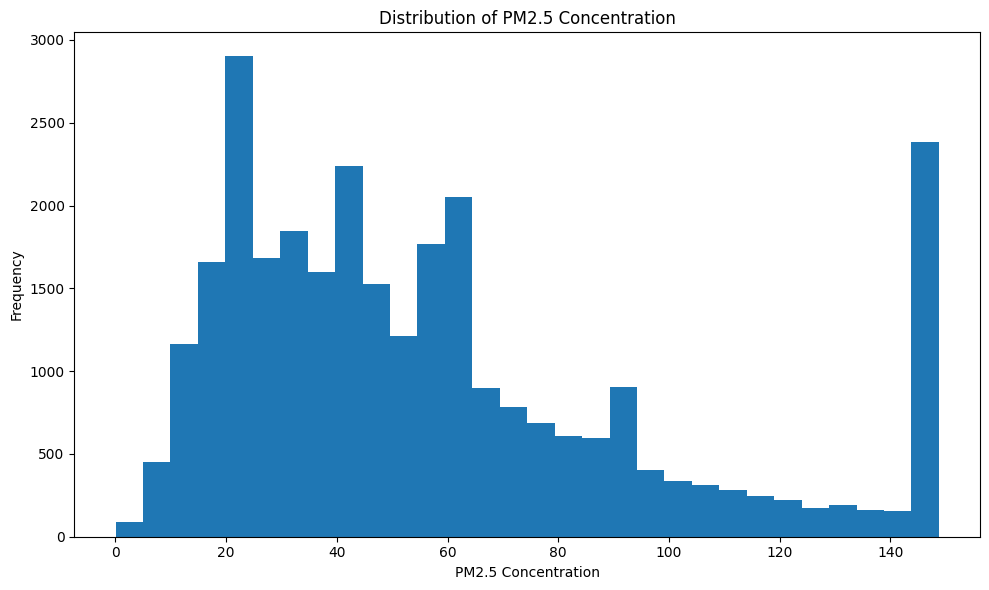

In [604]:
print("U4. PM2.5 Distribution")

plt.figure(figsize=(10, 6))

plt.hist(df_clean["PM2.5"], bins=30)

plt.xlabel("PM2.5 Concentration")
plt.ylabel("Frequency")
plt.title("Distribution of PM2.5 Concentration")

plt.tight_layout()
plt.show()

**Analysis:** The histogram represents the frequency distribution of PM2.5 concentrations. It helps examine the spread of particulate matter levels and identify the concentration ranges where most observations occur.

5. PM10 Distribution:

U5. PM10 Distribution


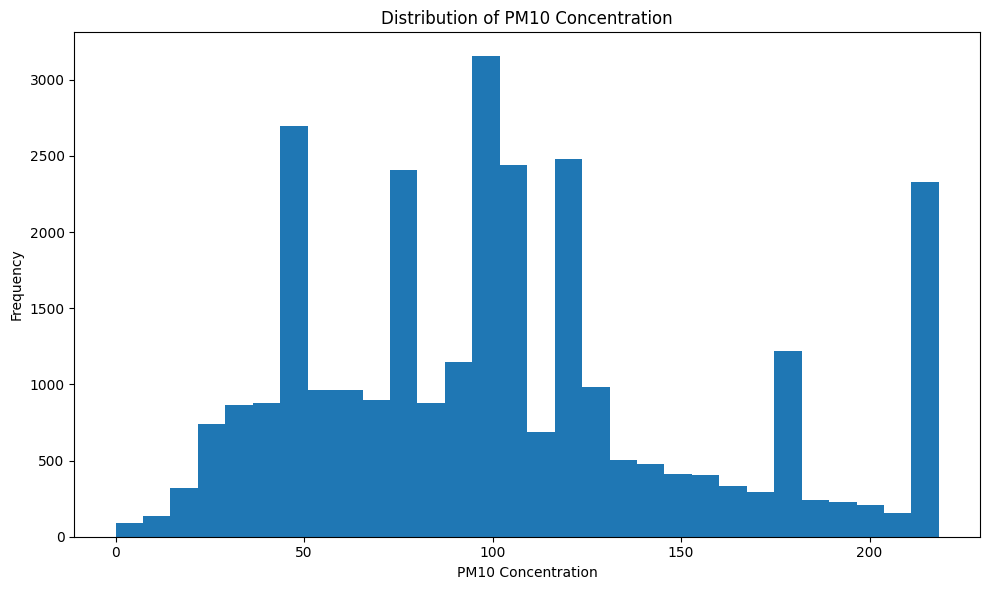

In [605]:
print("U5. PM10 Distribution")

plt.figure(figsize=(10, 6))

plt.hist(df_clean["PM10"], bins=30)

plt.xlabel("PM10 Concentration")
plt.ylabel("Frequency")
plt.title("Distribution of PM10 Concentration")

plt.tight_layout()
plt.show()

**Analysis:** The histogram shows how PM10 concentration values are distributed across the dataset. It helps understand the variation in PM10 levels and identify the ranges with higher frequencies.

6. Major Pollutants Boxplot:

U6. Major Pollutants Boxplot


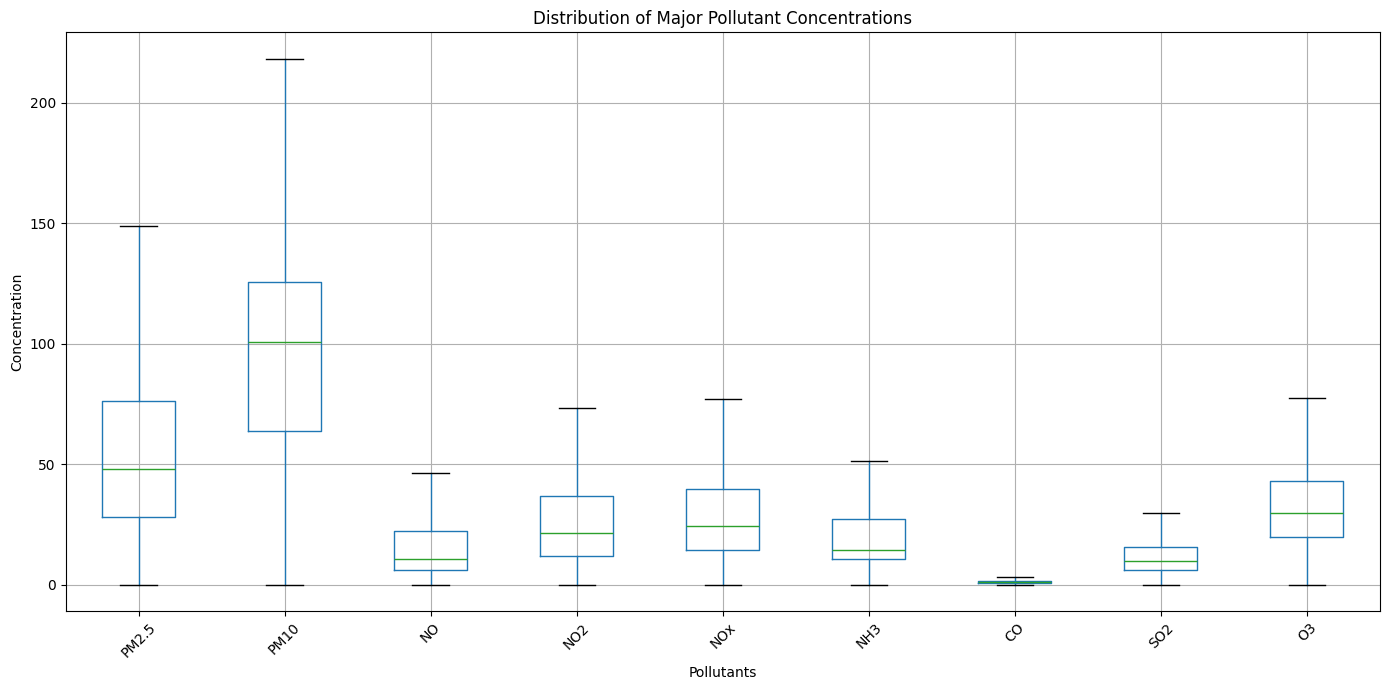

In [606]:
print("U6. Major Pollutants Boxplot")

major_pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3"
]

plt.figure(figsize=(14, 7))

df_clean[major_pollutants].boxplot()

plt.xlabel("Pollutants")
plt.ylabel("Concentration")
plt.title("Distribution of Major Pollutant Concentrations")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Findings:** Boxplots are used to compare the distributions of major pollutants, including PM2.5, PM10, NO, NO2, NOx, NH3, CO, SO2 and O3. They help examine differences in median values, spread and potential extreme observations.

7. City-wise AQI Distribution:

U8. City-wise AQI Distribution


<Figure size 1600x800 with 0 Axes>

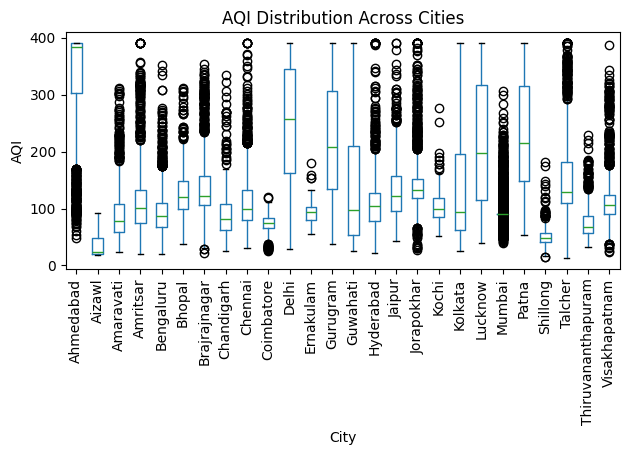

In [607]:
print("U8. City-wise AQI Distribution")

plt.figure(figsize=(16, 8))

df_clean.boxplot(
    column="AQI",
    by="City",
    grid=False
)

plt.xlabel("City")
plt.ylabel("AQI")
plt.title("AQI Distribution Across Cities")
plt.suptitle("")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Insights:** The boxplot compares AQI distributions across different cities. It helps identify variations in median AQI, pollution spread and potential extreme values among the cities.

**Bivariate Visualizations:**

1. PM2.5 vs AQI — Scatter Plot:

B1. PM2.5 vs AQI


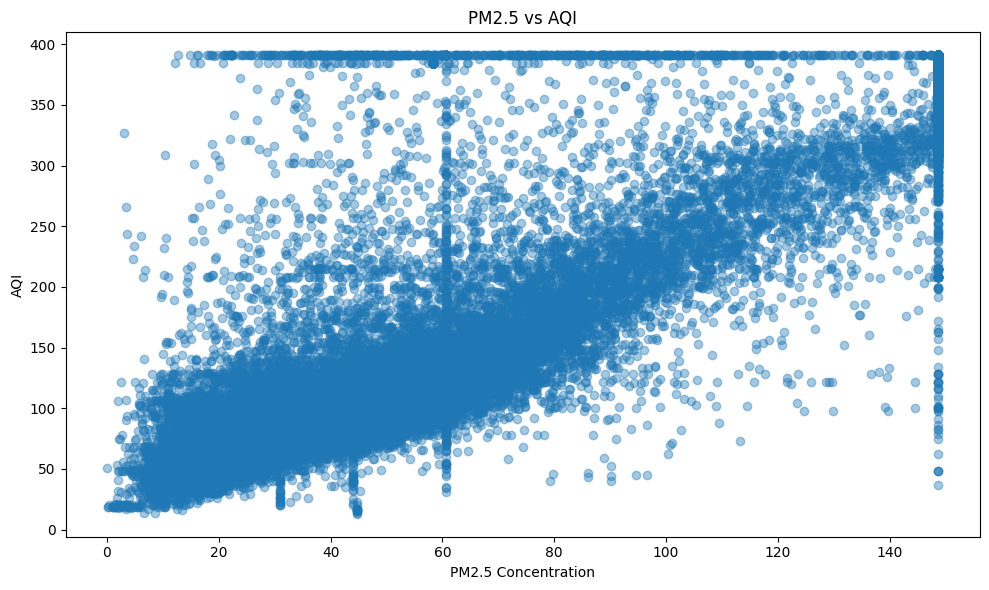

In [608]:
print("B1. PM2.5 vs AQI")

plt.figure(figsize=(10, 6))

plt.scatter(df_clean["PM2.5"], df_clean["AQI"], alpha=0.4)

plt.xlabel("PM2.5 Concentration")
plt.ylabel("AQI")
plt.title("PM2.5 vs AQI")

plt.tight_layout()
plt.show()

**Analysis:** The scatter plot examines the relationship between PM2.5 concentration and AQI. It helps identify whether changes in PM2.5 levels are associated with changes in the Air Quality Index.

2. PM10 vs AQI — Scatter Plot:

B2. PM10 vs AQI


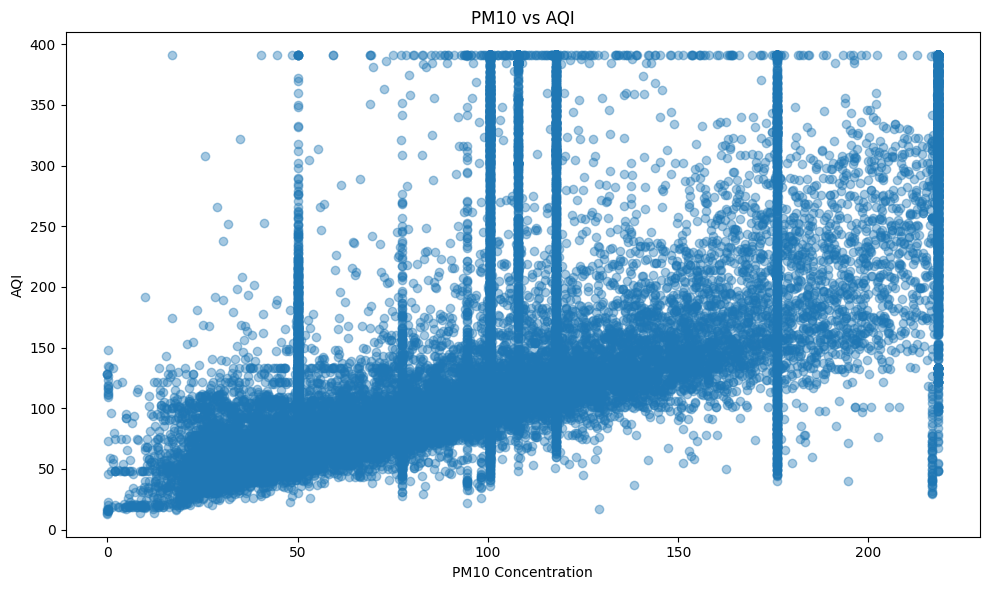

In [609]:
print("B2. PM10 vs AQI")

plt.figure(figsize=(10, 6))

plt.scatter(df_clean["PM10"], df_clean["AQI"], alpha=0.4)

plt.xlabel("PM10 Concentration")
plt.ylabel("AQI")
plt.title("PM10 vs AQI")

plt.tight_layout()
plt.show()

**Analysis:** The scatter plot compares PM10 concentration with AQI to understand their relationship. It helps reveal the association between particulate pollution and overall air quality.

3. CO vs AQI — Bar Plot:

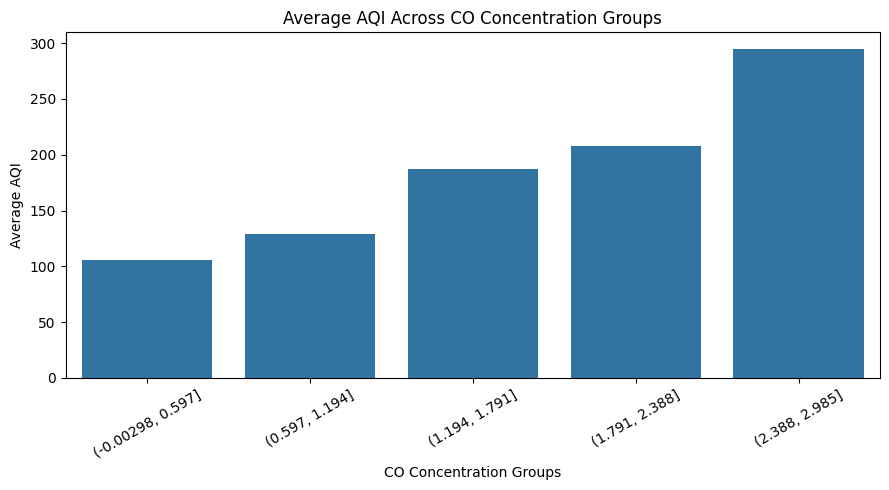

In [610]:
plot_data = df_clean[["CO", "AQI"]].dropna().copy()

plot_data["CO_Group"] = pd.cut(
    plot_data["CO"],
    bins=5
)

co_aqi = plot_data.groupby(
    "CO_Group", observed=True
)["AQI"].mean().reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(data=co_aqi, x="CO_Group", y="AQI")

plt.title("Average AQI Across CO Concentration Groups")
plt.xlabel("CO Concentration Groups")
plt.ylabel("Average AQI")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Observations:** CO concentrations are divided into groups, and the average AQI is calculated for each group. The bar plot helps compare air-quality levels across different CO concentration ranges.

4. SO2 vs AQI — Boxplot:

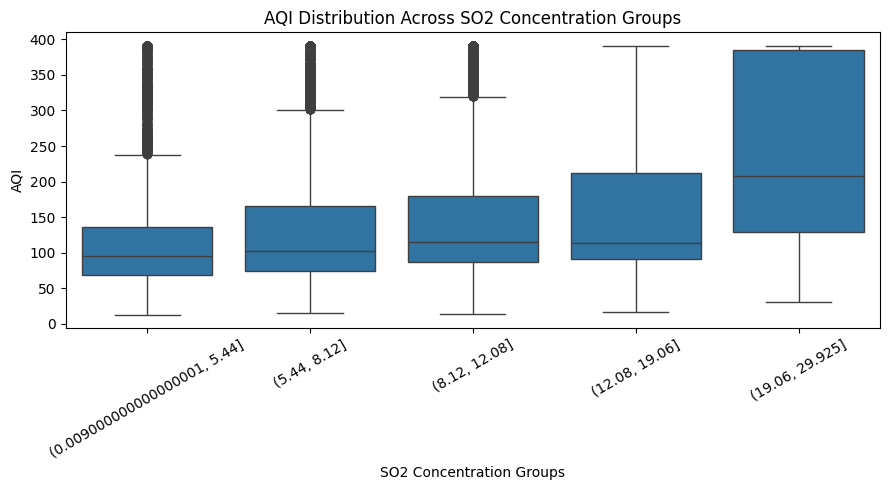

In [611]:
plot_data = df_clean[["SO2", "AQI"]].dropna().copy()

plot_data["SO2_Group"] = pd.qcut(
    plot_data["SO2"],
    q=5,
    duplicates="drop"
)

plt.figure(figsize=(9, 5))

sns.boxplot(data=plot_data, x="SO2_Group", y="AQI")

plt.title("AQI Distribution Across SO2 Concentration Groups")
plt.xlabel("SO2 Concentration Groups")
plt.ylabel("AQI")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Findings:** The boxplot compares AQI distributions across different SO2 concentration groups. It highlights differences in median AQI, spread and potential extreme values between the groups.

5. NO2 vs AQI — Line Plot:

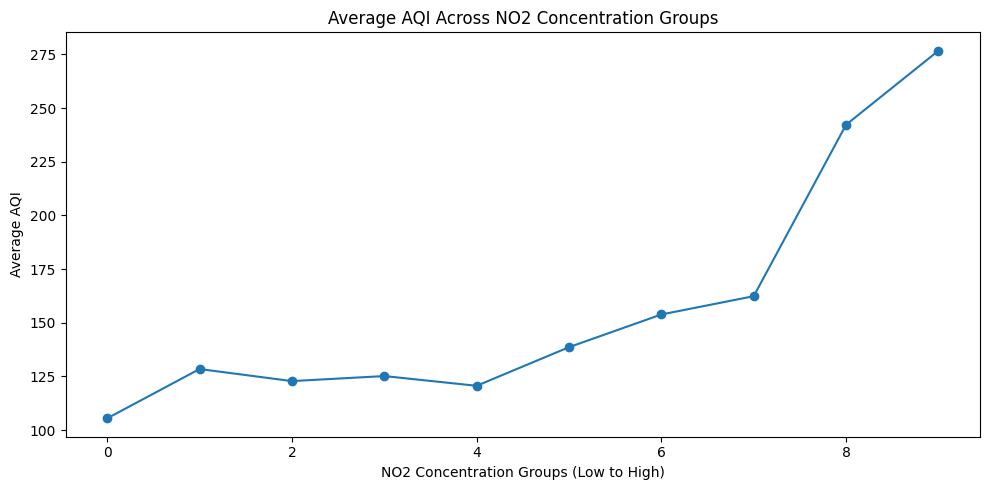

In [612]:
plot_data = df_clean[["NO2", "AQI"]].dropna().copy()

plot_data["NO2_Group"] = pd.qcut(
    plot_data["NO2"],
    q=10,
    duplicates="drop"
)

no2_aqi = plot_data.groupby(
    "NO2_Group", observed=True
)["AQI"].mean().reset_index()

plt.figure(figsize=(10, 5))

plt.plot(
    range(len(no2_aqi)),
    no2_aqi["AQI"],
    marker="o"
)

plt.title("Average AQI Across NO2 Concentration Groups")
plt.xlabel("NO2 Concentration Groups (Low to High)")
plt.ylabel("Average AQI")
plt.tight_layout()
plt.show()

**Analysis:** NO2 concentrations are divided into groups, and the average AQI is plotted for each group. The line plot helps identify how average air quality changes across increasing NO2 concentration ranges.

6. City vs Average AQI — Bar Chart:

B6. City vs Average AQI


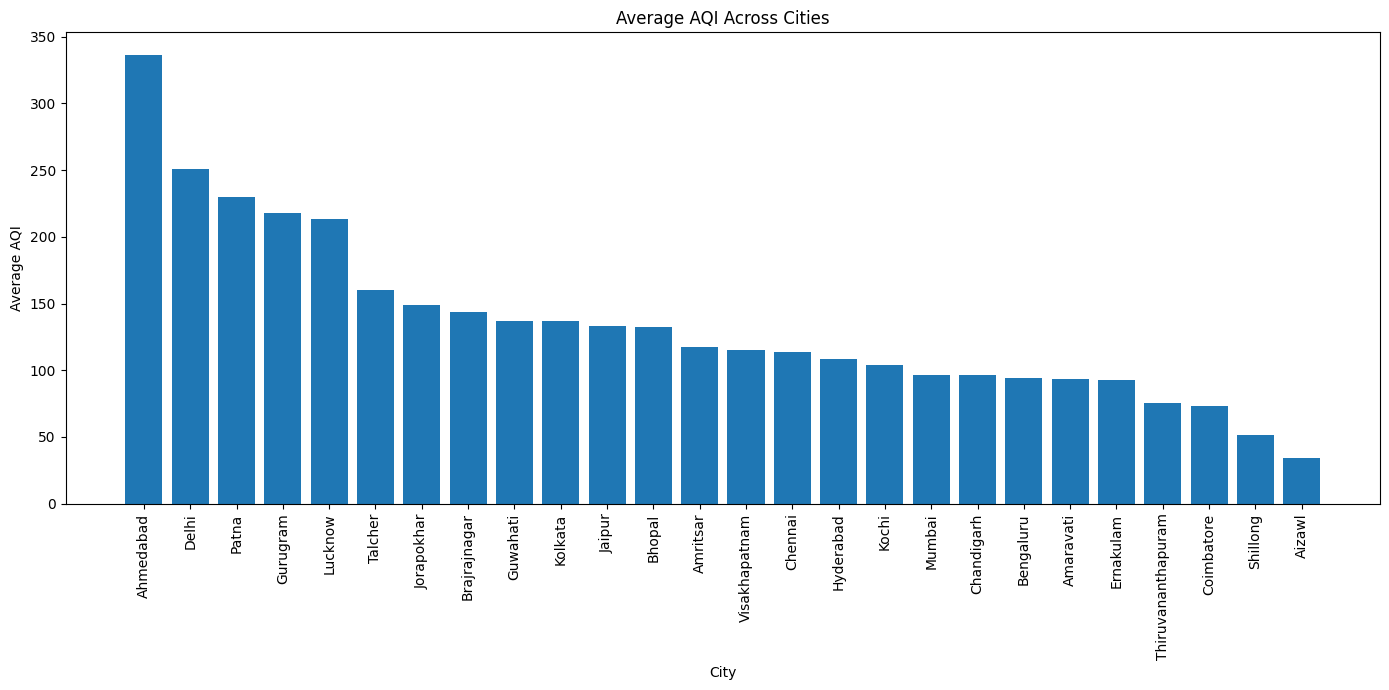

In [613]:
print("B6. City vs Average AQI")

city_aqi = (
    df_clean.groupby("City")["AQI"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 7))

plt.bar(city_aqi.index, city_aqi.values)

plt.xlabel("City")
plt.ylabel("Average AQI")
plt.title("Average AQI Across Cities")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Findings:** The bar chart compares the average AQI values across different cities. It helps identify geographical differences in air quality and highlights cities with relatively higher or lower average AQI.

7. AQI Category vs PM2.5 — Boxplot:

B7. AQI Category vs PM2.5


/tmp/ipykernel_2681/484771573.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=categories)


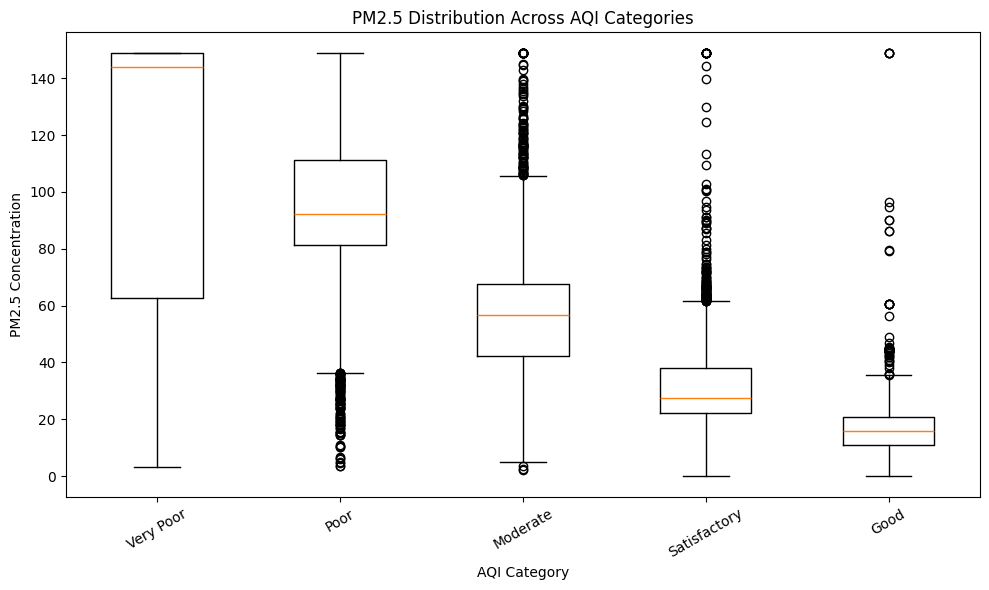

In [614]:
print("B7. AQI Category vs PM2.5")

categories = df_clean["AQI_Bucket"].unique()

data = [
    df_clean[df_clean["AQI_Bucket"] == category]["PM2.5"]
    for category in categories
]

plt.figure(figsize=(10, 6))

plt.boxplot(data, labels=categories)

plt.xlabel("AQI Category")
plt.ylabel("PM2.5 Concentration")
plt.title("PM2.5 Distribution Across AQI Categories")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Observations:** The boxplot compares PM2.5 concentration across different AQI categories. It helps understand how particulate matter levels vary between air-quality classifications.

## Week 4 – Conclusion

The Exploratory Data Analysis (EDA) provided a clear understanding of the Air Quality Index (AQI) and pollutant characteristics in the cleaned dataset. Univariate analysis was used to study the distribution and variation of AQI and major pollutants, while bivariate analysis was used to examine relationships between pollutants and AQI and compare AQI levels across cities.

The analysis revealed noticeable variation in air quality and pollutant concentrations across the dataset. These findings provide useful insights into the pollution patterns and form the basis for further analysis and interpretation of the air quality data.

#**Week 6 — Feature Engineering**

1. Skewness Analysis of Numerical Features

In [615]:
from scipy.stats import skew

print("Skewness Analysis of Pollutants")
print("-" * 50)

for column in numerical_pollutants:
    values = df_clean[column].dropna()
    skewness = skew(values)

    if skewness > 1:
        interpretation = "Highly right-skewed"
    elif skewness > 0.5:
        interpretation = "Moderately right-skewed"
    elif skewness < -1:
        interpretation = "Highly left-skewed"
    elif skewness < -0.5:
        interpretation = "Moderately left-skewed"
    else:
        interpretation = "Approximately symmetric"

    print(f"{column}: Skewness = {skewness:.2f} - {interpretation}")

Skewness Analysis of Pollutants
--------------------------------------------------
PM2.5: Skewness = 1.02 - Highly right-skewed
PM10: Skewness = 0.62 - Moderately right-skewed
NO: Skewness = 1.19 - Highly right-skewed
NO2: Skewness = 0.98 - Moderately right-skewed
NOx: Skewness = 0.93 - Moderately right-skewed
NH3: Skewness = 0.95 - Moderately right-skewed
CO: Skewness = 0.91 - Moderately right-skewed
SO2: Skewness = 0.97 - Moderately right-skewed
O3: Skewness = 0.66 - Moderately right-skewed
Benzene: Skewness = 1.23 - Highly right-skewed
Toluene: Skewness = 1.17 - Highly right-skewed


**Findings:**
- Highly right-skewed: PM2.5 (1.02), NO (1.19), Benzene (1.23), Toluene (1.17).
- Moderately right-skewed: PM10, NO2, NOx, NH3, CO, SO2 and O3.
- All 11 pollutant features show right-skewed distributions.

2. Skewness Correction Using Log Transformation

In [616]:
import numpy as np

transformed_df = df_clean.copy()

for column in numerical_pollutants:
    transformed_df[column + "_log"] = np.log1p(transformed_df[column])

print("Skewness Before and After Log Transformation")
print("-" * 60)

for column in numerical_pollutants:
    before = transformed_df[column].skew()
    after = transformed_df[column + "_log"].skew()
    print(f"{column}: Before = {before:.2f}, After = {after:.2f}")

Skewness Before and After Log Transformation
------------------------------------------------------------
PM2.5: Before = 1.02, After = -0.30
PM10: Before = 0.62, After = -1.16
NO: Before = 1.19, After = -0.22
NO2: Before = 0.98, After = -0.60
NOx: Before = 0.93, After = -1.26
NH3: Before = 0.95, After = -0.53
CO: Before = 0.91, After = 0.19
SO2: Before = 0.97, After = -0.10
O3: Before = 0.66, After = -1.20
Benzene: Before = 1.23, After = 0.45
Toluene: Before = 1.17, After = 0.14


**Analysis:**
- Log1p transformation was applied to all 11 pollutant features.
- Skewness decreased for several features, while PM10, NOx and O3 became left-skewed.
- The transformation helped reduce the original right skewness in the pollutant data.

3. Visualize Before and After Transformation

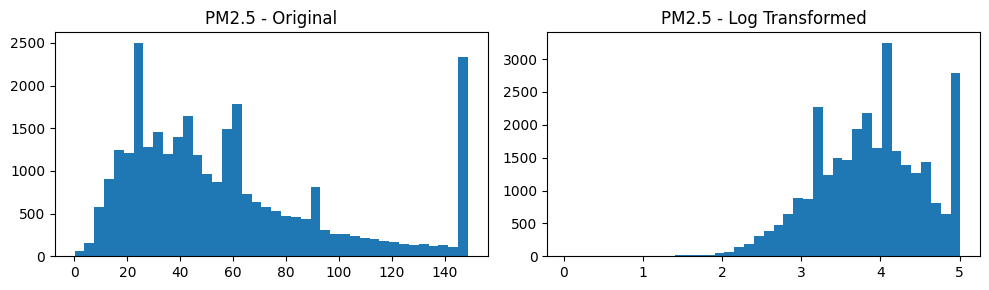

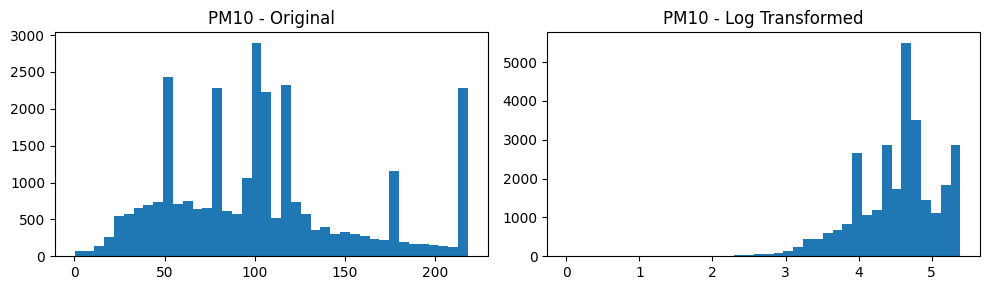

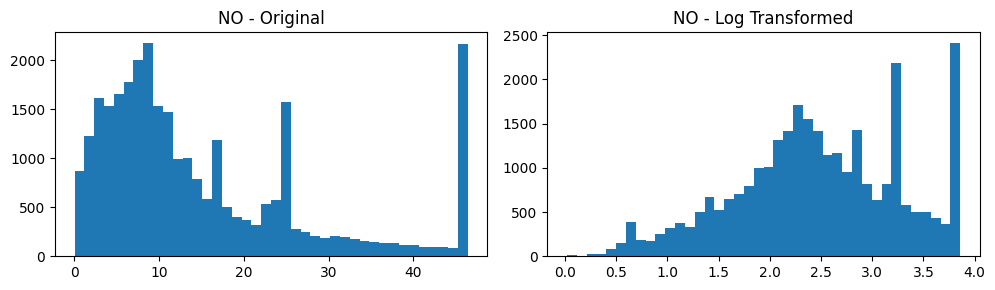

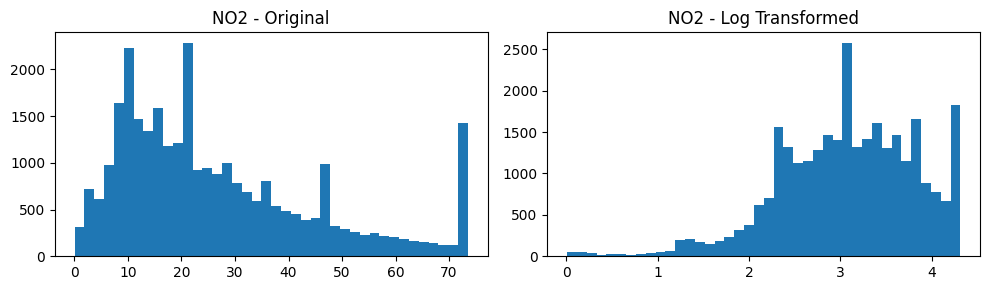

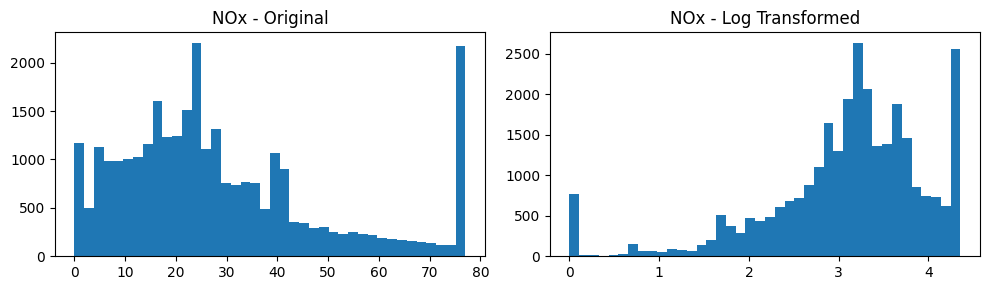

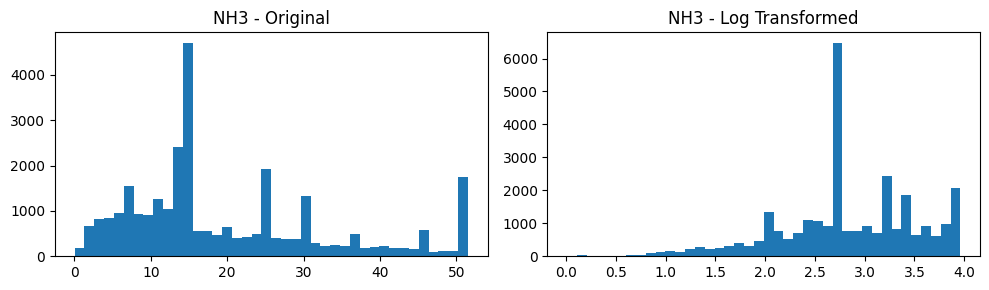

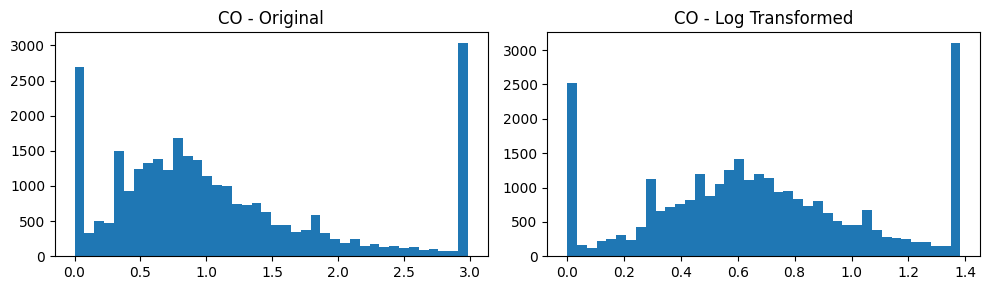

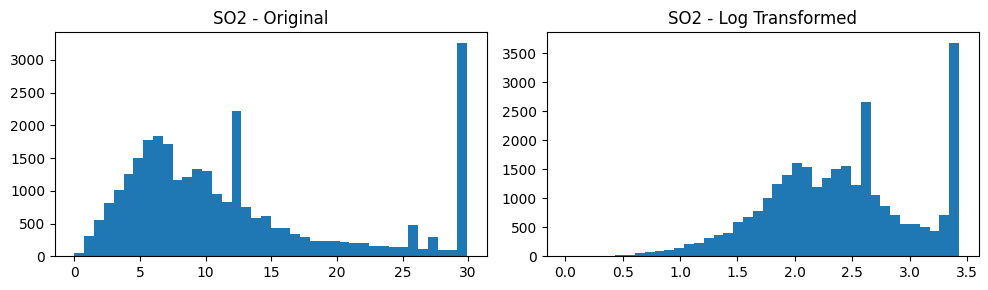

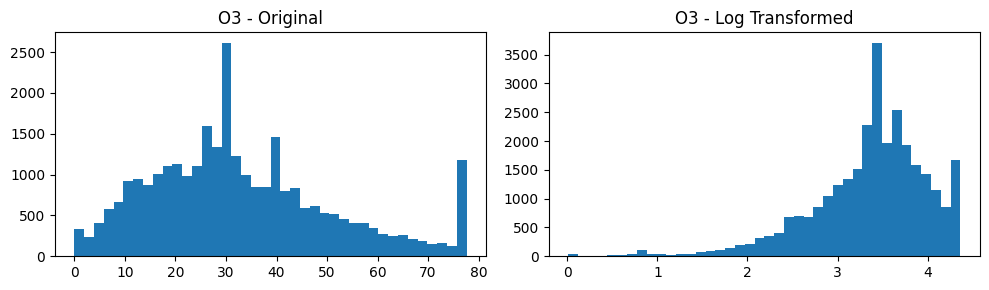

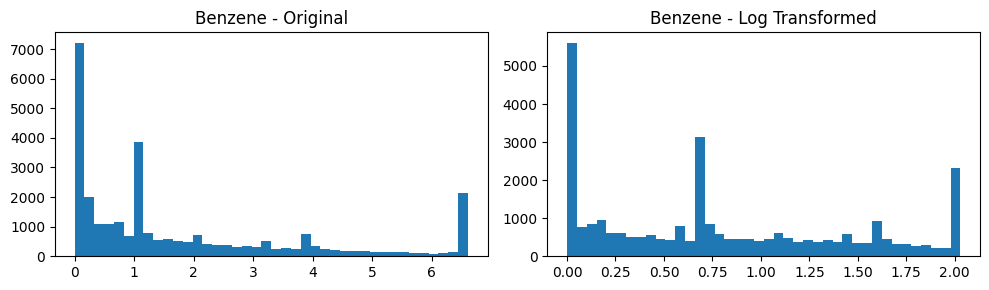

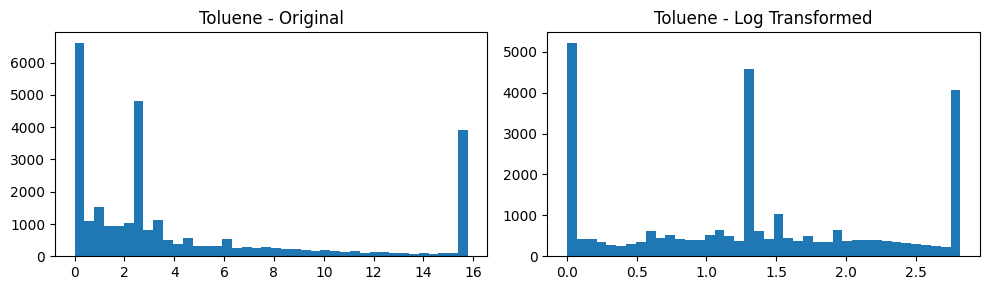

In [617]:
import matplotlib.pyplot as plt

for column in numerical_pollutants:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))

    axes[0].hist(df_clean[column].dropna(), bins=40)
    axes[0].set_title(f"{column} - Original")

    axes[1].hist(transformed_df[column + "_log"].dropna(), bins=40)
    axes[1].set_title(f"{column} - Log Transformed")

    plt.tight_layout()
    plt.show()

**Observations:** The histograms compare the original and log-transformed distributions of all 11 pollutants. They help visualize how log transformation changes the shape and spread of each feature.

4. Decide Which Transformations to Keep

In [618]:
print("Transformation Effectiveness")
print("-" * 60)

for column in numerical_pollutants:
    before = df_clean[column].skew()
    after = transformed_df[column + "_log"].skew()

    improvement = abs(before) - abs(after)

    if abs(after) <= 0.5:
        decision = "Good improvement"
    elif abs(after) < abs(before):
        decision = "Skewness reduced"
    else:
        decision = "No improvement"

    print(
        f"{column}: Before = {before:.2f}, "
        f"After = {after:.2f}, "
        f"{decision}"
    )

Transformation Effectiveness
------------------------------------------------------------
PM2.5: Before = 1.02, After = -0.30, Good improvement
PM10: Before = 0.62, After = -1.16, No improvement
NO: Before = 1.19, After = -0.22, Good improvement
NO2: Before = 0.98, After = -0.60, Skewness reduced
NOx: Before = 0.93, After = -1.26, No improvement
NH3: Before = 0.95, After = -0.53, Skewness reduced
CO: Before = 0.91, After = 0.19, Good improvement
SO2: Before = 0.97, After = -0.10, Good improvement
O3: Before = 0.66, After = -1.20, No improvement
Benzene: Before = 1.23, After = 0.45, Good improvement
Toluene: Before = 1.17, After = 0.14, Good improvement


**Findings:**
- Good improvement: PM2.5, NO, CO, SO2, Benzene and Toluene.
- Skewness reduced: NO2 and NH3.
- No improvement: PM10, NOx and O3.
- The comparison identifies which transformations were more effective.

5. Select Features for Further Analysis

In [619]:
log_features = transformed_df[
    [column + "_log" for column in numerical_pollutants]
].copy()

print("Log-Transformed Features")
print("-" * 50)
print("Dataset shape:", log_features.shape)
print("\nFirst five rows:")
print(log_features.head())

Log-Transformed Features
--------------------------------------------------
Dataset shape: (29531, 11)

First five rows:
   PM2.5_log  PM10_log    NO_log   NO2_log   NOx_log  NH3_log    CO_log  \
0   4.083789  4.690981  0.652325  2.955951  2.898671  2.74084  0.652325   
1   4.083789  4.690981  0.678034  2.814810  2.859913  2.74084  0.678034   
2   4.083789  4.690981  2.912351  3.010621  3.424263  2.74084  1.382537   
3   4.083789  4.690981  0.993252  2.969388  2.942859  2.74084  0.993252   
4   4.083789  4.690981  3.139833  3.109953  3.657389  2.74084  1.382537   

    SO2_log    O3_log  Benzene_log  Toluene_log  
0  3.354804  4.364658     0.000000     0.019803  
1  3.240637  3.557061     1.543298     1.871802  
2  3.403528  3.456317     2.028806     2.820188  
3  2.975019  3.613078     1.691939     2.410542  
4  3.431565  3.696600     2.028806     2.820188  


**Explanation:** The 11 log-transformed pollutant features were selected and stored separately in `log_features`. The resulting dataset contains 29,531 rows and 11 columns for further analysis.

6. Feature Scaling

In [620]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

scaler = StandardScaler()

scaled_features = pd.DataFrame(
    scaler.fit_transform(log_features),
    columns=log_features.columns,
    index=log_features.index
)

print("Standardized Features")
print("-" * 50)
print("Dataset shape:", scaled_features.shape)
print("\nFirst five rows:")
print(scaled_features.head())

print("\nFeature means:")
print(scaled_features.mean().round(2))

print("\nFeature standard deviations:")
print(scaled_features.std().round(2))

Standardized Features
--------------------------------------------------
Dataset shape: (29531, 11)

First five rows:
   PM2.5_log  PM10_log    NO_log   NO2_log   NOx_log   NH3_log    CO_log  \
0   0.314683  0.301516 -2.235144 -0.160696 -0.222614 -0.117427 -0.052676   
1   0.314683  0.301516 -2.203730 -0.348062 -0.265331 -0.117427  0.012961   
2   0.314683  0.301516  0.526471 -0.088123  0.356678 -0.117427  1.811656   
3   0.314683  0.301516 -1.818552 -0.142859 -0.173911 -0.117427  0.817757   
4   0.314683  0.301516  0.804440  0.043742  0.613623 -0.117427  1.811656   

    SO2_log    O3_log  Benzene_log  Toluene_log  
0  1.498041  1.536930    -1.201321    -1.374767  
1  1.319758  0.307388     1.140587     0.589862  
2  1.574127  0.154008     1.877331     1.595923  
3  0.904970  0.392672     1.366145     1.161365  
4  1.617909  0.519831     1.877331     1.595923  

Feature means:
PM2.5_log     -0.0
PM10_log       0.0
NO_log        -0.0
NO2_log        0.0
NOx_log        0.0
NH3_log       

**Findings:**
- StandardScaler was applied to all 11 log-transformed features.
- Feature means are approximately 0.
- Feature standard deviations are approximately 1.
- The scaled dataset contains 29,531 rows and 11 columns.

7. Categorical Feature Encoding

In [621]:
print("Categorical Feature Analysis")
print("-" * 50)

categorical_columns = df_clean.select_dtypes(
    include=["object", "category"]
).columns

for column in categorical_columns:
    print(f"\n{column}")
    print("Unique values:", df_clean[column].nunique())
    print("Sample categories:", df_clean[column].dropna().unique()[:10])

Categorical Feature Analysis
--------------------------------------------------

City
Unique values: 26
Sample categories: ['Ahmedabad' 'Aizawl' 'Amaravati' 'Amritsar' 'Bengaluru' 'Bhopal'
 'Brajrajnagar' 'Chandigarh' 'Chennai' 'Coimbatore']

Date
Unique values: 2009
Sample categories: ['2015-01-01' '2015-01-02' '2015-01-03' '2015-01-04' '2015-01-05'
 '2015-01-06' '2015-01-07' '2015-01-08' '2015-01-09' '2015-01-10']

AQI_Bucket
Unique values: 5
Sample categories: ['Very Poor' 'Poor' 'Moderate' 'Satisfactory' 'Good']


**Observations:**
- City: 26 unique values.
- Date: 2,009 unique values.
- AQI_Bucket: 5 unique values in the cleaned dataset.
- These columns require suitable handling depending on the purpose of the analysis.

8. One-Hot Encoding for City

In [622]:
city_encoded = pd.get_dummies(
    df_clean["City"],
    prefix="City",
    dtype=int
)

print("One-Hot Encoding of City")
print("-" * 50)
print("Original unique cities:", df_clean["City"].nunique())
print("Encoded dataset shape:", city_encoded.shape)
print("\nFirst five rows:")
print(city_encoded.head())

One-Hot Encoding of City
--------------------------------------------------
Original unique cities: 26
Encoded dataset shape: (29531, 26)

First five rows:
   City_Ahmedabad  City_Aizawl  City_Amaravati  City_Amritsar  City_Bengaluru  \
0               1            0               0              0               0   
1               1            0               0              0               0   
2               1            0               0              0               0   
3               1            0               0              0               0   
4               1            0               0              0               0   

   City_Bhopal  City_Brajrajnagar  City_Chandigarh  City_Chennai  \
0            0                  0                0             0   
1            0                  0                0             0   
2            0                  0                0             0   
3            0                  0                0             0   
4            0   

**Findings:**
- The 26 unique cities were converted into 26 binary columns.
- Each column represents a city using 0s and 1s.
- The encoded dataset contains 29,531 rows and 26 columns.

9. Label Encoding for AQI_Bucket

In [623]:
from sklearn.preprocessing import LabelEncoder

print("Label Encoding of AQI_Bucket")
print("-" * 50)

label_encoder = LabelEncoder()

aqi_bucket_encoded = df_clean["AQI_Bucket"].dropna()
aqi_bucket_encoded = label_encoder.fit_transform(aqi_bucket_encoded)

print("Category mapping:")
for category, number in zip(label_encoder.classes_, range(len(label_encoder.classes_))):
    print(f"{category}: {number}")

print("\nFirst 10 encoded values:")
print(aqi_bucket_encoded[:10])

Label Encoding of AQI_Bucket
--------------------------------------------------
Category mapping:
Good: 0
Moderate: 1
Poor: 2
Satisfactory: 3
Very Poor: 4

First 10 encoded values:
[4 4 4 4 4 4 4 4 4 4]


**Explanation:** Label encoding converts the AQI_Bucket categories into numerical labels. In the displayed output, five categories are mapped from 0 to 4, and the encoded values are stored separately from the main dataset.

10. Binning and Discretization

In [624]:
print("AQI Binning and Discretization")
print("-" * 50)

aqi_bins = [0, 50, 100, 200, 300, 400, float("inf")]
aqi_labels = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

aqi_binned = pd.cut(
    df["AQI"],
    bins=aqi_bins,
    labels=aqi_labels,
    include_lowest=True
)

print("AQI category counts after binning:")
print(aqi_binned.value_counts(sort=False))

valid_aqi = df["AQI"].dropna()

print("\nOriginal AQI sample:")
print(valid_aqi.head(10).tolist())

print("\nBinned AQI sample:")
print(pd.cut(
    valid_aqi.head(10),
    bins=aqi_bins,
    labels=aqi_labels,
    include_lowest=True
).tolist())

AQI Binning and Discretization
--------------------------------------------------
AQI category counts after binning:
AQI
Good            1341
Satisfactory    8224
Moderate        8829
Poor            2781
Very Poor       2337
Severe          1338
Name: count, dtype: int64

Original AQI sample:
[209.0, 328.0, 514.0, 782.0, 914.0, 660.0, 294.0, 149.0, 190.0, 247.0]

Binned AQI sample:
['Poor', 'Very Poor', 'Severe', 'Severe', 'Severe', 'Severe', 'Poor', 'Moderate', 'Moderate', 'Poor']


**Observations:**
- AQI values were grouped into six categories: Good, Satisfactory, Moderate, Poor, Very Poor and Severe.
- Moderate has the highest count (8,829), followed by Satisfactory (8,224).
- This makes AQI values easier to interpret and compare.

11. Apply and Visualize Transformations

Applying and Visualizing Transformations
--------------------------------------------------


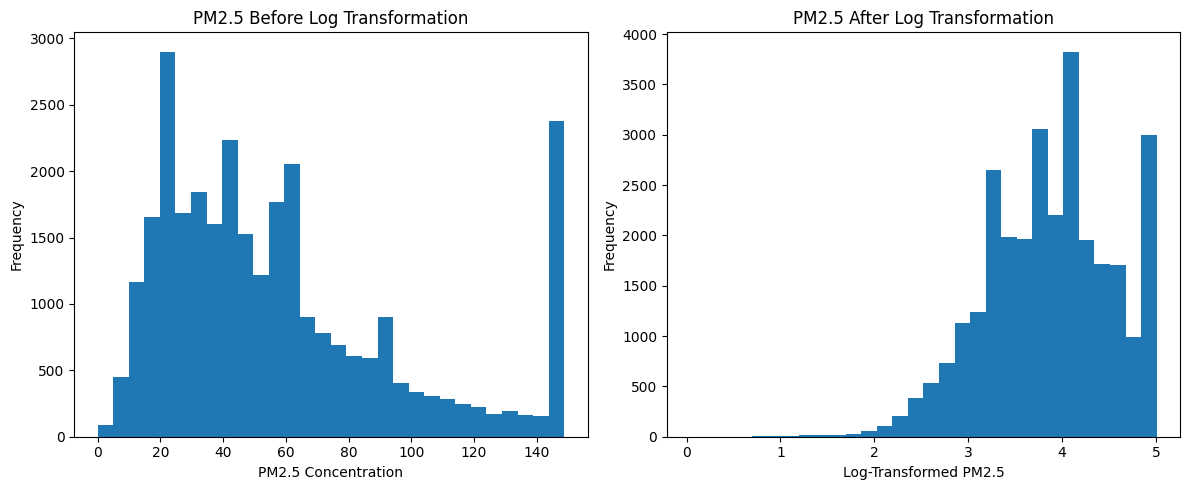

Original PM2.5 skewness: 1.02
Transformed PM2.5 skewness: -0.3


In [625]:
print("Applying and Visualizing Transformations")
print("-" * 50)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(df_clean["PM2.5"].dropna(), bins=30)
axes[0].set_title("PM2.5 Before Log Transformation")
axes[0].set_xlabel("PM2.5 Concentration")
axes[0].set_ylabel("Frequency")

axes[1].hist(np.log1p(df_clean["PM2.5"].dropna()), bins=30)
axes[1].set_title("PM2.5 After Log Transformation")
axes[1].set_xlabel("Log-Transformed PM2.5")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print("Original PM2.5 skewness:", round(df_clean["PM2.5"].skew(), 2))
print("Transformed PM2.5 skewness:", round(np.log1p(df_clean["PM2.5"].dropna()).skew(), 2))

**Analysis:** The original and log-transformed PM2.5 distributions are compared using histograms. The skewness changes from 1.02 to -0.30, showing that log transformation reduced the right skewness.

12. Verify Week 6 Feature Engineering Results

In [626]:
print("Week 6 Feature Engineering Summary")
print("-" * 50)

print("Log-Transformed Features Shape:", log_features.shape)
print("Standardized Features Shape:", scaled_features.shape)
print("One-Hot Encoded City Shape:", city_encoded.shape)

print("\nMissing Values in Log-Transformed Features:")
print(log_features.isnull().sum().sum())

print("\nMissing Values in Standardized Features:")
print(scaled_features.isnull().sum().sum())

print("\nFeature Scaling Verification:")
print("Mean of first feature:", round(scaled_features.iloc[:, 0].mean(), 2))
print("Standard deviation of first feature:", round(scaled_features.iloc[:, 0].std(), 2))

print("\nWeek 6 verification completed.")

Week 6 Feature Engineering Summary
--------------------------------------------------
Log-Transformed Features Shape: (29531, 11)
Standardized Features Shape: (29531, 11)
One-Hot Encoded City Shape: (29531, 26)

Missing Values in Log-Transformed Features:
0

Missing Values in Standardized Features:
0

Feature Scaling Verification:
Mean of first feature: -0.0
Standard deviation of first feature: 1.0

Week 6 verification completed.


**Findings:**
- Log-transformed features: 29,531 rows × 11 columns.
- Standardized features: 29,531 rows × 11 columns.
- One-hot encoded City: 29,531 rows × 26 columns.
- Missing values in log-transformed and standardized features: 0.
- Standardized feature mean is approximately 0 and standard deviation is approximately 1.

**Week 6: Feature Engineering — Summary**

**Skewness Analysis:** Identified highly right-skewed distributions in the pollutant features.

**Skewness Correction:** Applied log transformation to reduce skewness in pollutant concentrations.
Feature Scaling: Standardized the transformed features to achieve a mean near 0 and a standard deviation of 1.

**Categorical Feature Analysis** Examined the City, Date, and AQI_Bucket columns and their unique values.

**One-Hot Encoding:** Converted the 26 cities into separate binary columns for analysis.

**Label Encoding:** Assigned numerical labels to the six AQI categories.

**AQI Binning and Discretization:** Grouped AQI values into six categories for easier interpretation.

**Transformation Visualization:** Compared PM2.5 distributions before and after log transformation to observe the reduction in skewness.

**Final Verification:** Confirmed that the log-transformed and standardized datasets each contain 29,531 rows and 11 features, with no missing values.

##Week-7 - Dimensionality Reduction

1. Prepare the Dataset for PCA

In [627]:

numerical_features = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene"
]

X = df_clean[numerical_features].dropna()

print("Rows:", X.shape[0])
print("Features:", X.shape[1])
print("Missing values:", X.isnull().sum().sum())

display(X.head())


Rows: 29531
Features: 11
Missing values: 0


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
0,58.37,107.96,0.92,18.22,17.15,14.5,0.920,27.640,77.6225,0.000,0.02
1,58.37,107.96,0.97,15.69,16.46,14.5,0.970,24.550,34.0600,3.680,5.50
2,58.37,107.96,17.40,19.30,29.70,14.5,2.985,29.070,30.7000,6.605,15.78
3,58.37,107.96,1.70,18.48,17.97,14.5,1.700,18.590,36.0800,4.430,10.14
4,58.37,107.96,22.10,21.42,37.76,14.5,2.985,29.925,39.3100,6.605,15.78


**Findings:**
- 11 numerical pollutant features were selected for PCA.
- Total records: 29,531.
- Missing values: 0.
- The dataset is ready for feature selection and dimensionality reduction.

2. Variance Thresholding for Feature Selection

In [628]:
from sklearn.feature_selection import VarianceThreshold
import pandas as pd

selector = VarianceThreshold(threshold=0.01)
X_variance = selector.fit_transform(X)

selected_features = X.columns[selector.get_support()]

X = pd.DataFrame(
    X_variance,
    columns=selected_features,
    index=X.index
)

print("Selected features:", list(X.columns))
print("Number of features:", X.shape[1])

Selected features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']
Number of features: 11


**Observations:** Variance thresholding with a threshold of 0.01 was applied to identify features with very low variance. All 11 pollutant features were retained because none fell below the selected threshold.

3. Correlation Matrix Analysis

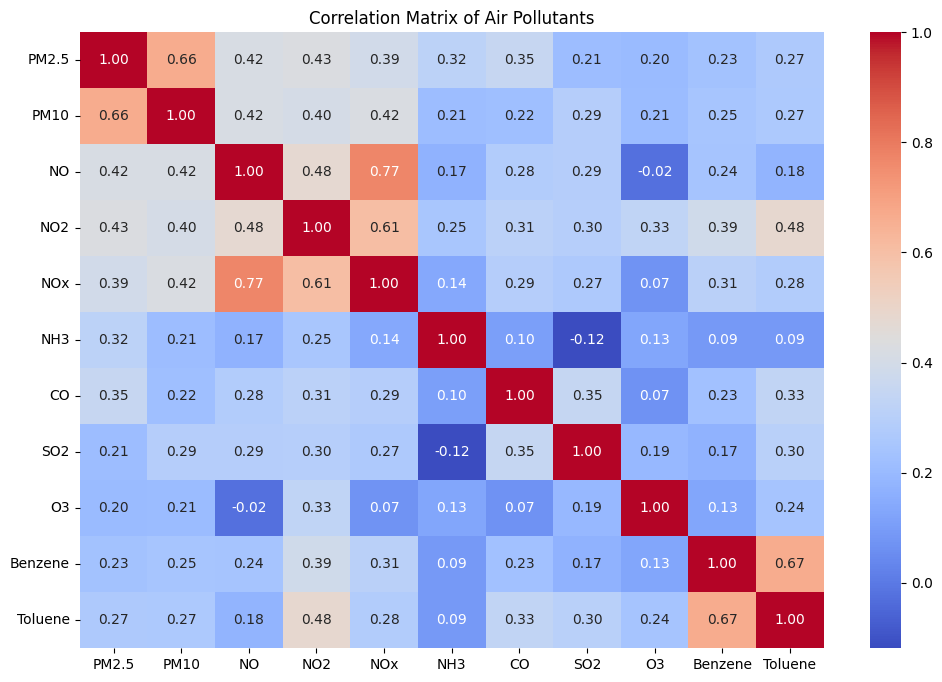

In [629]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_matrix = X.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Air Pollutants")
plt.show()


**Analysis:** The correlation matrix heatmap displays the relationships between different air pollutants. It helps identify strongly correlated features that may contain overlapping information and contribute to multicollinearity.

4. Remove Highly Correlated Features

In [630]:
correlation_matrix = X.corr().abs()

upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_corr_features = [
    column for column in upper_triangle.columns
    if any(upper_triangle[column] > 0.70)
]

print("Features removed:", high_corr_features)

X = X.drop(columns=high_corr_features)

print("Remaining features:", list(X.columns))
print("Number of features:", X.shape[1])

Features removed: ['NOx']
Remaining features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']
Number of features: 10


**Findings:**
- A correlation threshold of 0.70 was used.
- NOx was identified and removed due to high correlation.
- The remaining dataset contains 10 pollutant features.
- This step helps reduce redundancy among the selected features.

5. Feature Selection

In [631]:
import numpy as np

correlation_matrix = X.corr()
threshold = 0.70

upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_correlation = [
    (column, row, upper_triangle.loc[row, column])
    for column in upper_triangle.columns
    for row in upper_triangle.index
    if pd.notna(upper_triangle.loc[row, column])
    and abs(upper_triangle.loc[row, column]) >= threshold
]

print("Highly correlated pollutant pairs:")
for feature1, feature2, value in high_correlation:
    print(f"{feature1} - {feature2}: {value:.2f}")

print("\nTotal features retained:", X.shape[1])


Highly correlated pollutant pairs:

Total features retained: 10


**Inference:** After removing NOx, the correlation check found no remaining pollutant pairs meeting the 0.70 threshold. Therefore, all 10 remaining features were retained for further analysis.

6. Standardization

In [632]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original data shape:", X.shape)
print("Standardized data shape:", X_scaled.shape)
print("Mean of first feature:", round(X_scaled[:, 0].mean(), 2))
print("Standard deviation of first feature:", round(X_scaled[:, 0].std(), 2))


Original data shape: (29531, 10)
Standardized data shape: (29531, 10)
Mean of first feature: -0.0
Standard deviation of first feature: 1.0


**Findings:**
- StandardScaler was applied to the 10 selected features.
- Original dataset shape: 29,531 × 10.
- Standardized dataset shape: 29,531 × 10.
- Mean of the first feature: approximately 0.
- Standard deviation of the first feature: 1.0.

7. Principal Component Analysis (PCA)

In [633]:
from sklearn.decomposition import PCA

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

print("Original number of features:", X_scaled.shape[1])
print("Number of principal components:", X_pca.shape[1])
print("PCA data shape:", X_pca.shape)


Original number of features: 10
Number of principal components: 10
PCA data shape: (29531, 10)


**Explanation:** PCA was applied to the standardized dataset to transform the 10 original pollutant features into 10 principal components. These components represent combinations of the original features and help reduce dimensionality while retaining important information.

8. Principal Component Loading Analysis

In [634]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=[f"PC{i+1}" for i in range(X.shape[1])]
)

print("Component weights:")
display(loadings.round(3))

print("\nTop contributing features for PC1:")
print(loadings["PC1"].abs().sort_values(ascending=False).head(5))

Component weights:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
PM2.5,0.382,0.376,0.039,0.054,-0.050,-0.423,-0.153,0.070,0.704,-0.052
PM10,0.368,0.312,0.090,0.148,-0.361,-0.421,0.103,0.063,-0.643,0.028
NO,0.324,0.238,0.352,-0.232,-0.236,0.524,-0.135,-0.458,0.034,0.318
NO2,0.406,-0.012,-0.122,0.025,-0.059,0.487,-0.293,0.618,-0.070,-0.325
NH3,0.173,0.481,-0.460,-0.199,0.419,0.181,0.524,-0.048,-0.053,-0.002
CO,0.292,-0.107,0.316,-0.088,0.761,-0.185,-0.333,-0.122,-0.233,-0.054
SO2,0.266,-0.273,0.470,0.387,0.066,0.131,0.644,0.043,0.153,-0.151
O3,0.194,-0.097,-0.446,0.724,0.054,0.120,-0.214,-0.400,-0.010,0.073
Benzene,0.315,-0.406,-0.253,-0.404,-0.216,-0.133,0.075,-0.403,0.013,-0.525
Toluene,0.354,-0.462,-0.238,-0.188,-0.004,-0.125,0.104,0.239,0.057,0.695



Top contributing features for PC1:
NO2        0.406279
PM2.5      0.381794
PM10       0.368478
Toluene    0.354003
NO         0.324496
Name: PC1, dtype: float64


**Findings:**
- Component loadings show how strongly each pollutant contributes to the principal components.
- The top contributing features for PC1 are:
  - NO2: 0.406
  - PM2.5: 0.382
  - PM10: 0.368
  - Toluene: 0.354
  - NO: 0.324
- These features have the highest absolute loading values for PC1.

9. Explained Variance Ratio

PC1: 0.3556 (35.56%)
PC2: 0.1323 (13.23%)
PC3: 0.1135 (11.35%)
PC4: 0.1002 (10.02%)
PC5: 0.0788 (7.88%)
PC6: 0.0698 (6.98%)
PC7: 0.0530 (5.30%)
PC8: 0.0396 (3.96%)
PC9: 0.0298 (2.98%)
PC10: 0.0275 (2.75%)


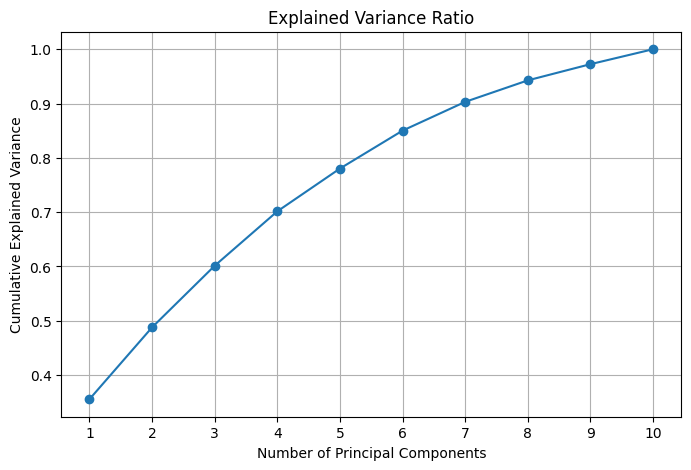

Variance retained by first 2 components: 48.79 %
Components needed for 95% variance: 9


In [635]:
import numpy as np
import matplotlib.pyplot as plt

explained_variance = pca.explained_variance_ratio_

for i, value in enumerate(explained_variance, 1):
    print(f"PC{i}: {value:.4f} ({value * 100:.2f}%)")

cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Explained Variance Ratio")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid(True)
plt.show()

print("Variance retained by first 2 components:",
      round(cumulative_variance[1] * 100, 2), "%")
print("Components needed for 95% variance:",
      np.argmax(cumulative_variance >= 0.95) + 1)


**Observations:**
- PC1 explains 35.56% of the total variance.
- PC2 explains 13.23% of the total variance.
- The first two components together retain 48.79% of the variance.
- 9 principal components are required to retain at least 95% of the total variance.

10. Principal Component Visualization

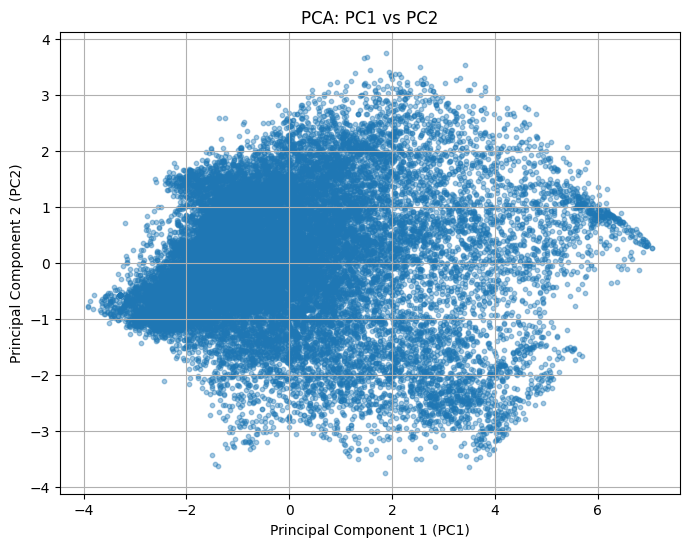

In [636]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.4,
    s=10
)

plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.title("PCA: PC1 vs PC2")
plt.grid(True)
plt.show()


**Analysis:** The scatter plot represents the observations using the first two principal components, PC1 and PC2. It provides a two-dimensional view of the transformed data and helps examine the distribution and possible grouping of observations.

11. Create and Save the Reduced PCA Dataset

In [637]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

# Find components needed to retain 95% variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
n_components = np.argmax(cumulative_variance >= 0.95) + 1

# Create reduced PCA dataset
pca_reduced = PCA(n_components=n_components)
X_reduced = pca_reduced.fit_transform(X_scaled)

df_reduced = pd.DataFrame(
    X_reduced,
    columns=[f"PC{i+1}" for i in range(n_components)],
    index=X.index
)

# Save the reduced dataset
df_reduced.to_csv("city_day_pca_reduced.csv", index=False)

print("Reduced dataset saved!")
print("Original feature count:", X.shape[1])
print("Reduced feature count:", n_components)
print(
    "Variance retained:",
    round(pca_reduced.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

display(df_reduced.head())

Reduced dataset saved!
Original feature count: 10
Reduced feature count: 9
Variance retained: 97.25 %


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
0,-0.299925,-0.380714,-0.033559,3.362528,0.372208,-0.112743,0.637839,-0.473378,0.216795
1,0.040818,-1.271598,0.193898,0.538007,-0.131244,-0.895900,1.181299,-0.112809,0.263623
2,2.467251,-2.826500,0.867400,-0.840823,1.024723,-0.942906,0.869147,-0.896549,-0.036321
3,0.626101,-1.722340,-0.220436,-0.052815,0.362986,-1.186930,0.489154,-0.166327,0.003503
4,2.752660,-2.813301,0.819467,-0.541033,0.963093,-0.623590,0.749301,-1.181515,-0.021031


**Explanation:** The PCA-transformed data is organized into a reduced dataset and saved for future use. This makes the dimensionality-reduced features available for subsequent analysis and visualization.

###Week 7 Summary

**Inference:** Week 7 focused on feature selection, correlation analysis, standardization and Principal Component Analysis. One highly correlated feature (NOx) was removed, reducing the pollutant features from 11 to 10. PCA transformed the remaining features into principal components, with the first two explaining 48.79% of the total variance and nine components retaining at least 95%.